# histo2mri demo: pipeline steps

Runs the whole registration of a single histology section to its MRI, one pipeline step per
section, showing what each step decides. `histo2mri.pipeline.register_section` does exactly
this sequence in one call; here it is unrolled so every intermediate result is visible.

## 0. Setup

Imports the package from the repository root, so the notebook runs
without installing it. The package log messages (the same ones that go into
`<section>_process.log` in a batch run) are sent to the notebook output.

In [1]:
import logging
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch

# Repository root = the parent of notebook/, so `import histo2mri` works uninstalled.
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from histo2mri import canvas, inverse, io, matching, outliers, plane, preprocessing, qc, refine, tps
from histo2mri.pipeline import (FINE_MATCH_W_NGF, FINE_MATCH_Z_HALF_MM, FOLD_FIX_INPLANE_SCALES,
                                MATCHER_SETTINGS, PROFILES)

%matplotlib inline
print("histo2mri from:", os.path.relpath(os.path.dirname(io.__file__)))
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())

histo2mri from: ../histo2mri
torch: 2.15.0+cu132 | cuda available: True


In [2]:
# Show the package's own step messages in the notebook. VERBOSE=True adds the per-scale and
# per-iteration detail (logger.debug) of the searches and the refinement.
VERBOSE = False

import warnings

# skimage 0.26 deprecates binary_dilation; the call is inside the package, and the warning
# is noise here. Remove this once preprocessing uses morphology.dilation.
warnings.filterwarnings("ignore", message=".*binary_dilation.*")

_pkg_logger = logging.getLogger("histo2mri")
for _h in list(_pkg_logger.handlers):
    _pkg_logger.removeHandler(_h)
_handler = logging.StreamHandler(sys.stdout)
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_pkg_logger.addHandler(_handler)
_pkg_logger.setLevel(logging.DEBUG if VERBOSE else logging.INFO)
_pkg_logger.propagate = False

## 1. The section, and where to get it

This demo uses one publicly available section:

> **NextBrain** — Iglesias Gonzalez, Casamitjana, Atzeni, Billot, Thomas, Blackburn et al.,
> *Registered histology, MRI, and manual annotations of over 300 brain regions in 5 human
> hemispheres*, University College London, 2023.
> [doi:10.5522/04/24243835.v1](https://doi.org/10.5522/04/24243835.v1), CC0-1.0.
>
> Subject **NB_EX9-19**, block **P2.3**, section **06**, H&E stain.

The data is not shipped with the package. Download it from the DOI above and arrange it in the
BIDS layout the README describes, where that section becomes
`sub-NBEX919` / `sample-P2306` / `stain-HE`:

```
<BIDS_ROOT>/
  sub-NBEX919/anat/sub-NBEX919_T1w.nii.gz
  sub-NBEX919/micr/sub-NBEX919_sample-P2306_stain-HE_BF.json
  derivatives/brainmask/sub-NBEX919/anat/sub-NBEX919_desc-brain_mask.nii.gz
  derivatives/cleanslide/sub-NBEX919/micr/sub-NBEX919_sample-P2306_stain-HE_desc-clean_BF.tif
                                          ..._desc-clean_BF.json
                                          ..._desc-tissue_mask.tif
```

The NextBrain slides are raw scans, so
[cleanslide](https://github.com/spittayapong/cleanslide) was run on this section first: it
removes the background and the mounting artifacts, crops to the tissue, and writes the
greyscale histology, its tissue mask and the pixel size that the cells below read. Histology
that has already been cleaned elsewhere does not need that step.

When no mounting information comes with the dataset, the three fields that place the section
in the MRI frame — `SectionOrientation`, `SectionRotation`, `SectionFlip` — have to be filled
in manually in the raw `micr` sidecar; for this section they are `coronal`, `0` and `x`.

Set `BIDS_ROOT` below, or the `HISTO2MRI_BIDS` environment variable, to point at your data.

In [3]:
# ---- Section ----
BIDS_ROOT = os.environ.get("HISTO2MRI_BIDS", os.path.join("..", "..", "data", "bids"))
SUBJECT = "NBEX919"               # sub-NBEX919  (NextBrain NB_EX9-19)
SAMPLE = "P2306"                  # sample-P2306 (block P2.3, section 06)
STAIN = "HE"                      # optional; needed only when a sample has several stains
PROFILE = "default"               # "default" or "he-cblock"

# ---- Parameters (the defaults of register_section and the CLI) ----
PAD_MULTIPLE = 64                   # the prepared histology is padded to a multiple of this (not the matching patch size)
PCLIP = (1, 99)                   # MRI intensity normalisation percentiles
SCALE_MAX = 1.30                  # upper end of the histology scale search
SCALE_STEP = 0.05
RANSAC_SAMPLE_SIZE = 3            # matches per RANSAC TPS hypothesis; 3 for sparse sections
LAM_AREA = 2.0                    # refinement rigidity: area (properness)
LAM_SHAPE = 0.0                   # refinement rigidity: shape (orthonormality)
W_RIGID_MODE = "mask"             # mask / conf / edge / none
MRI_ON_HISTO_TILE_SIZE = 2048     # checkerboard tile (HR px); 2048 suits 4 um histology
DEVICE = None                     # None -> cuda:0 when available

# ---- Output ----
# Relative, so the paths in the output below stay independent of where the repo sits.
OUT_DIR = os.path.join("..", "results", "demo_nextbrain")
SAVE_FIGURES = False              # also write the pipeline's QC PNGs to OUT_DIR
SAVE_TRANSFORM = False            # write <section>_transform_grid.npz in step 18

In [4]:
# Resolve the section the way register_section does: the files, then the sidecar fields.
paths = io.resolve_section(BIDS_ROOT, SUBJECT, SAMPLE, STAIN)
SECTION_ID = paths["base"]

metadata = io.read_section_metadata(paths["section_sidecar"])
orientation, rotation, flip = metadata["orientation"], metadata["rotation"], metadata["flip"]
spacing = io.read_pixel_size_mm(paths["histo_sidecar"])

if PROFILE not in PROFILES:
    raise ValueError(f"Unknown profile {PROFILE!r}; expected one of {list(PROFILES)}")
settings = PROFILES[PROFILE]
device = torch.device(DEVICE or ("cuda:0" if torch.cuda.is_available() else "cpu"))
matcher = dict(MATCHER_SETTINGS, device=device)

os.makedirs(OUT_DIR, exist_ok=True)
PREFIX = os.path.join(OUT_DIR, SECTION_ID)


def out_file(suffix):
    # Path of a QC file in OUT_DIR, or None when SAVE_FIGURES is off.
    return f"{PREFIX}_{suffix}" if SAVE_FIGURES else None


section_start = time.perf_counter()
print(f"section     : {SECTION_ID}")
print(f"from sidecar: {orientation}, rotation {rotation:g} deg, flip {flip}")
print(f"             histology spacing {tuple(round(s, 5) for s in spacing)} mm")
print(f"profile     : {PROFILE} {settings}")
print(f"device      : {device}")
print(f"out dir     : {OUT_DIR}")

section     : sub-NBEX919_sample-P2306_stain-HE
from sidecar: coronal, rotation 0 deg, flip (True, False, False)
             histology spacing (0.004, 0.004, 0.004) mm
profile     : default {'outlier_plane_dist': 20.0, 'outlier_knn': {'k': 8, 'plane_mad_k': 3.0, 'tukey_k': 3.0, 'cc_radius_scale': 3.0}, 'refine_similarity_weights': (1.0, 0.0)}
device      : cuda:0
out dir     : ../results/demo_nextbrain


In [5]:
# Display helpers. These only draw; no pipeline logic lives here.

def as_2d(x, idx=0):
    # x as a 2D float array (SimpleITK image, torch tensor or array; 3D -> slice idx).
    if isinstance(x, sitk.Image):
        x = sitk.GetArrayFromImage(x)
    elif torch.is_tensor(x):
        x = x.detach().cpu().numpy()
    x = np.asarray(x)
    if x.ndim == 3:
        x = x[idx]
    return x.astype(np.float32)


def show(images, titles=None, cmap="gray", size=5.0, suptitle=None, **imshow_kw):
    # A row of 2D images with a shared figure title.
    if not isinstance(images, (list, tuple)):
        images = [images]
    titles = titles or [""] * len(images)
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        im = ax.imshow(as_2d(img), cmap=cmap, **imshow_kw)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    fig.tight_layout()
    plt.show()


def describe(name, img):
    # Size, spacing and intensity range of an image.
    arr = sitk.GetArrayFromImage(img) if isinstance(img, sitk.Image) else np.asarray(img)
    line = f"{name:<22} shape(z,y,x)={arr.shape}"
    if isinstance(img, sitk.Image):
        line += f"  spacing(x,y,z)={tuple(round(s, 5) for s in img.GetSpacing())}"
    finite = arr[np.isfinite(arr)]
    if finite.size:
        line += f"  range=[{finite.min():.4g}, {finite.max():.4g}]"
    print(line)

## Step 1. Load the section and its MRI

`io.load_section` reads the greyscale histology, its tissue mask and the optional RGB image
from the cleanslide derivative, and the MRI with its brain mask. It rotates the histology by
`SectionRotation` and then flips it by `SectionFlip`, reorients the MRI to LPS, and permutes
the MRI axes for `SectionOrientation`, so that the cutting plane is the MRI x-y plane and z is
the axis the matcher searches.

The two in-plane axes are then turned to `io.VIEW_AXES`: +x screen-right and +y screen-down in
the display FSLeyes and MRIcron show, which for a coronal section means +x Left and +y
Inferior. That is the picture `SectionRotation` and `SectionFlip` are judged against, so the
MRI slices below come out the same way up as in a viewer. `mri_view_flip` records which axes
were reversed, so the step can be undone back to the stored volume.

In [6]:
vols = io.load_section(BIDS_ROOT, SUBJECT, SAMPLE, STAIN)
Ih_hr, Mh_hr, Im, Mm = vols["Ih_hr"], vols["Mh_hr"], vols["Im"], vols["Mm"]
Ih_rgb_hr = vols.get("Ih_rgb_hr")

for name, img in [("histology HR", Ih_hr), ("histology mask HR", Mh_hr),
                  ("MRI", Im), ("MRI mask", Mm)]:
    describe(name, img)
print("RGB histology", "present" if Ih_rgb_hr is not None else "absent (the RGB overlay is skipped)")
axes = vols["mri_view_axes"]
print(f"\nMRI brought to {vols['mri_canonical']} and permuted {vols['mri_permute']} for "
      f"'{vols['orientation']}', then reversed in {vols['mri_view_flip']}")
print(f"             viewer frame: right = {axes[0]}, down = {axes[1]}, through = {axes[2]}")

histology HR           shape(z,y,x)=(1, 9655, 10788)  spacing(x,y,z)=(0.004, 0.004, 0.004)  range=[0, 255]
histology mask HR      shape(z,y,x)=(1, 9655, 10788)  spacing(x,y,z)=(0.004, 0.004, 0.004)  range=[0, 1]


MRI                    shape(z,y,x)=(450, 340, 220)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[0, 186.3]
MRI mask               shape(z,y,x)=(450, 340, 220)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[0, 1]
RGB histology present

MRI brought to LPS and permuted (0, 2, 1) for 'coronal', then reversed in (False, True, False)
             viewer frame: right = L, down = I, through = P


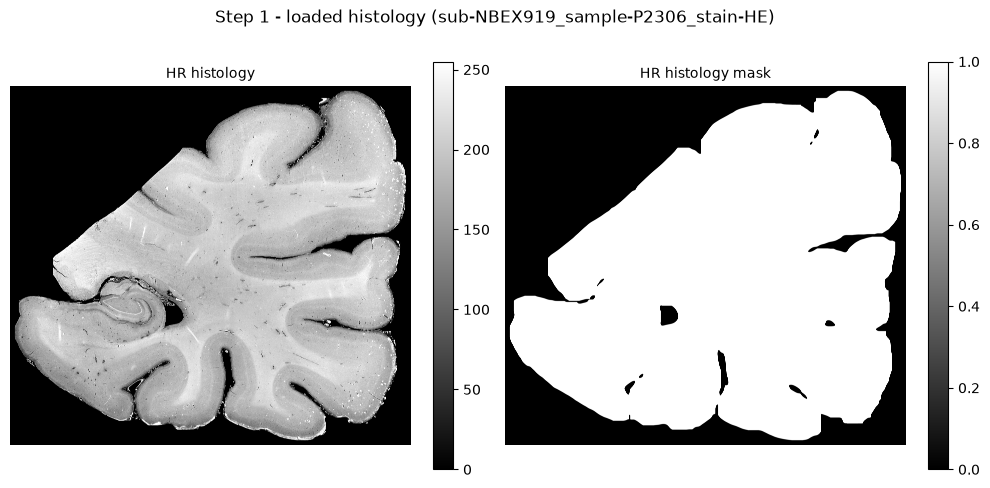

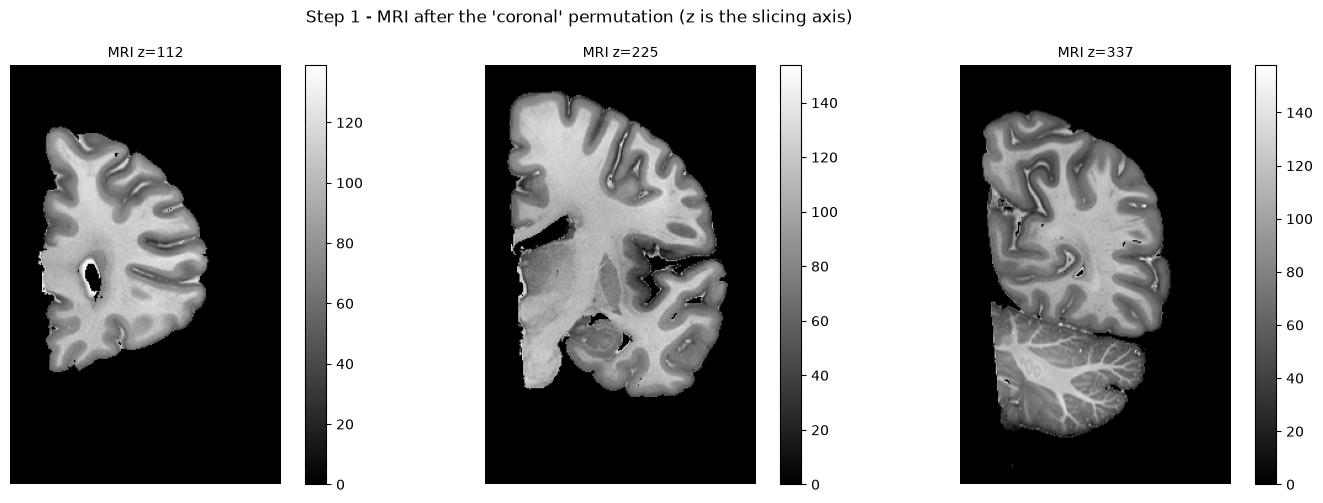

In [7]:
show([Ih_hr, Mh_hr], ["HR histology", "HR histology mask"],
     suptitle=f"Step 1 - loaded histology ({SECTION_ID})")

# Three MRI slices along the search axis z, after the orientation permutation.
Z = Im.GetSize()[2]
z_show = [Z // 4, Z // 2, 3 * Z // 4]
show([as_2d(Im, z) for z in z_show], [f"MRI z={z}" for z in z_show],
     suptitle=f"Step 1 - MRI after the '{orientation}' permutation (z is the slicing axis)")

anti-alias sigma (mm): (0.198, 0.198, 0.198)  =  49.5 histology pixels


histology LR           shape(z,y,x)=(1, 97, 108)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[-0.3675, 242.7]
histology mask LR      shape(z,y,x)=(1, 97, 108)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[0, 1]

A_hr_to_lr =
 [[0.01 0.   0.   0.  ]
 [0.   0.01 0.   0.  ]
 [0.   0.   0.01 0.  ]
 [0.   0.   0.   1.  ]]

downsampling factor (x, y) = 99.9, 99.5


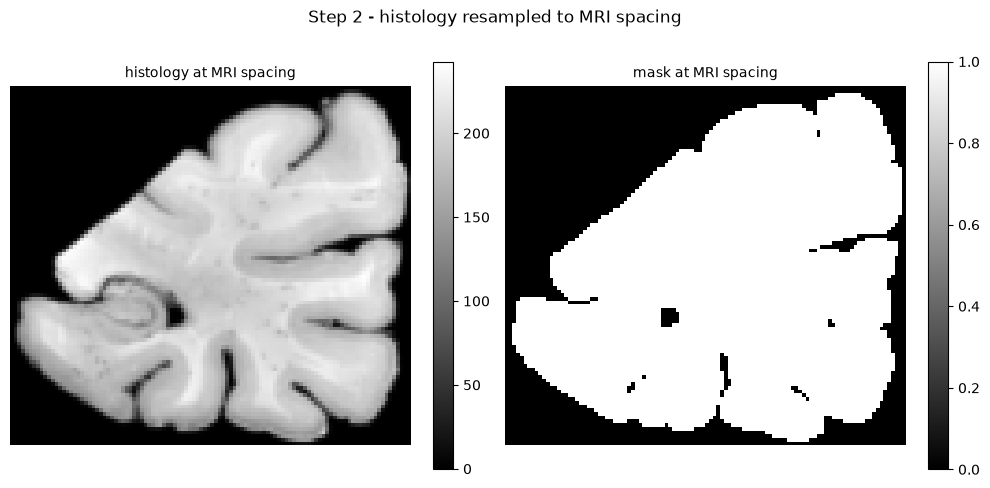

In [8]:
sigma_mm = preprocessing.anti_alias_sigma_mm(Ih_hr.GetSpacing(), Im.GetSpacing())
print(f"anti-alias sigma (mm): {tuple(round(s, 4) for s in sigma_mm)}"
      f"  =  {sigma_mm[0] / Ih_hr.GetSpacing()[0]:.1f} histology pixels")

Ih, Mh, A_hr_to_lr = preprocessing.resample_histo_to_mri(Ih_hr=Ih_hr, Mh_hr=Mh_hr, Im=Im)
describe("histology LR", Ih)
describe("histology mask LR", Mh)
print("\nA_hr_to_lr =\n", np.round(A_hr_to_lr, 6))
print(f"\ndownsampling factor (x, y) = "
      f"{Ih_hr.GetSize()[0] / Ih.GetSize()[0]:.1f}, {Ih_hr.GetSize()[1] / Ih.GetSize()[1]:.1f}")

show([Ih, Mh], ["histology at MRI spacing", "mask at MRI spacing"],
     suptitle="Step 2 - histology resampled to MRI spacing")

## Step 2. Histology to MRI spacing (HR to LR)

`preprocessing.resample_histo_to_mri` downsamples the histology to the MRI voxel size and
returns the HR to LR index affine. The histology is Gaussian-smoothed in plane first, with
`sigma = (spacing_mri - spacing_histo) / 2` per axis, because the downsampling factor is around
100 here and linear interpolation alone would alias cell-level texture into noise. The tissue
mask is not smoothed.

## Step 3. Prepare the histology (LR to proc)

`preprocessing.prepare_histology` pads the LR histology to a multiple of `PAD_MULTIPLE`, so that
the patch grid fits. Nothing is rescaled here (`scale_ratio = (1, 1)`); the shrinkage scale is
searched in step 5.

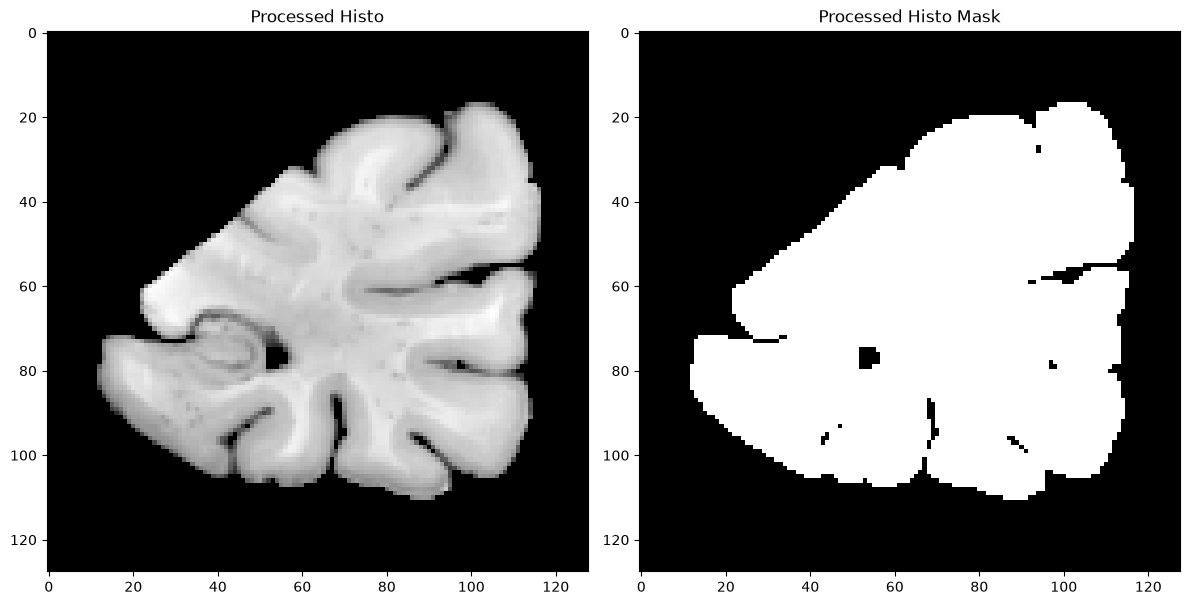

histology proc         shape(z,y,x)=(1, 128, 128)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[-0.3675, 242.7]
padded from (108, 97, 1) to (128, 128, 1) (multiple of 64)


In [9]:
scale_ratio = (1, 1)   # no resizing here; the shrinkage scale is searched in step 5
proc_Ih, proc_Mh, A_lr_to_proc = preprocessing.prepare_histology(
    Ih=Ih, Mh=Mh, scale_ratio=scale_ratio, pad_multiple=PAD_MULTIPLE,
    show_proc_img=True, save_file=out_file("proc_histo.png"),
)
A_hr_to_proc = A_lr_to_proc @ A_hr_to_lr
describe("histology proc", proc_Ih)
print("padded from", Ih.GetSize(), "to", proc_Ih.GetSize(), f"(multiple of {PAD_MULTIPLE})")

## Step 4. Prepare the MRI slab

`preprocessing.prepare_mri_slab` dilates the MRI mask by one voxel and rescales the intensities
to [0, 1] between the `PCLIP` percentiles inside that mask, zero outside. No slices are cropped.

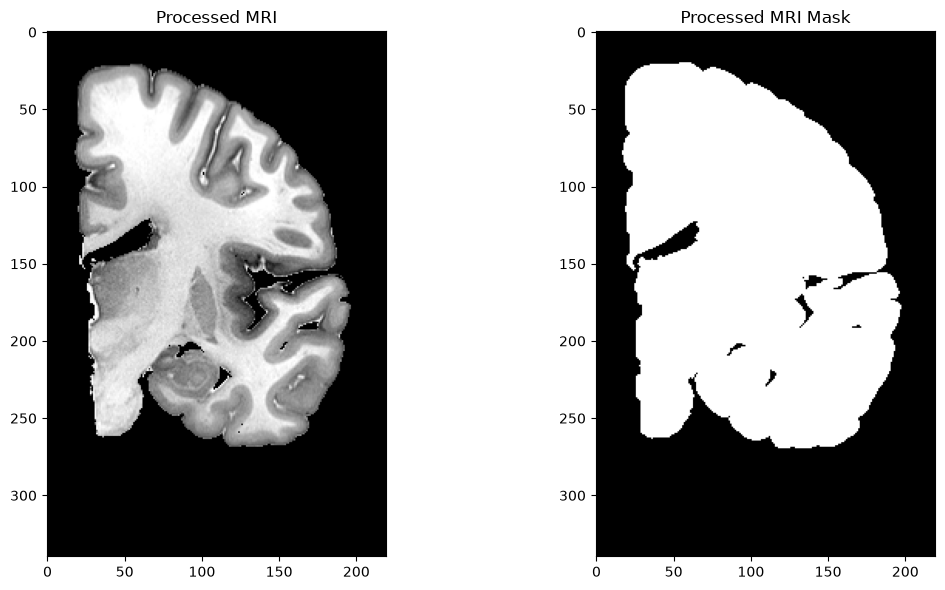

MRI slab               shape(z,y,x)=(450, 340, 220)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[0, 1]
MRI slab mask          shape(z,y,x)=(450, 340, 220)  spacing(x,y,z)=(0.4, 0.4, 0.4)  range=[0, 1]


In [10]:
n_slices = Im.GetSize()[2] // 2   # only the slice index of the display below
slab_raw_Im, slab_Im, slab_Mm = preprocessing.prepare_mri_slab(
    Im=Im, Mm=Mm, n_slices=n_slices, show_proc_img=True,
    save_file=out_file("proc_mri.png"), pclip=tuple(PCLIP),
)
describe("MRI slab", slab_Im)
describe("MRI slab mask", slab_Mm)

## Step 5. Find ROI: the histology scale

Histology shrinks during processing, so the section is smaller than the MRI plane it belongs
to. `matching.search_scale` resizes the histology over a grid of scale factors, matches each
against the whole MRI slab with the cached HOG + MIND matcher, and keeps the scale with the
highest robust match score (the median of the best 30 % of match scores).

This is the first expensive step: it builds the MRI patch bank once and then runs one matching
pass per scale.

In [11]:
scales = np.arange(1.00, SCALE_MAX + 1e-6, SCALE_STEP)
best_scale_info, scale_records = matching.search_scale(
    proc_Ih=proc_Ih, histo_mask=proc_Mh, slab_Im=slab_Im, slab_Mm=slab_Mm,
    scales=scales, common_kwargs=matcher,
)
best_scale = best_scale_info["scale"]
print(f"best scale = {best_scale:.3f}  (score {best_scale_info['score']:.4f})")
if abs(best_scale - SCALE_MAX) < 1e-6:
    print("note: the best scale is the end of the search range; widen SCALE_MAX to check "
          "whether the optimum lies beyond it")

df_scales = pd.DataFrame(scale_records).sort_values("scale").reset_index(drop=True)
df_scales

best scale = 1.300  (score 0.9834)
note: the best scale is the end of the search range; widen SCALE_MAX to check whether the optimum lies beyond it


,scale,score,n_matches,status,z_center,z_min,z_max
0,1.00,0.910681,4,ok,296,165,427
1,1.05,0.943537,4,ok,250,235,265
2,1.10,0.953869,4,ok,249,241,257
3,1.15,0.917922,4,ok,248,230,266
4,1.20,0.944468,4,ok,248,239,257
5,1.25,0.902969,4,ok,246,238,254
6,1.30,0.983433,4,ok,246,237,255


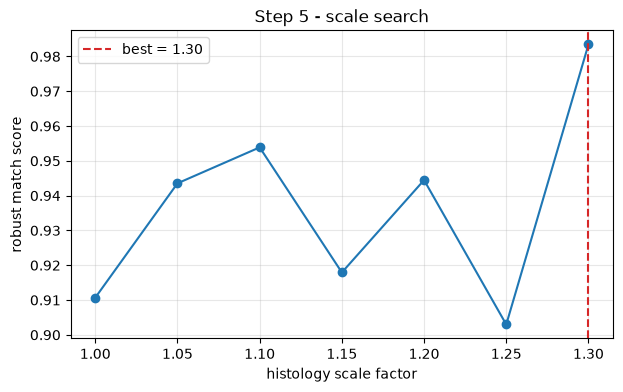

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_scales["scale"], df_scales["score"], "o-")
ax.axvline(best_scale, color="tab:red", ls="--", label=f"best = {best_scale:.2f}")
ax.set_xlabel("histology scale factor")
ax.set_ylabel("robust match score")
ax.set_title("Step 5 - scale search")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Step 6. Find ROI: patch size, strides and z centre

`matching.search_patch_config` runs the matcher at the chosen scale for each candidate patch
configuration and ranks them by RANSAC affine consistency (inlier count first). The slice band
of the best configuration gives `z_center`, which the fine matching is centred on.

In [13]:
patch_matrix = [
    {"patch": 96, "hist_stride": 64, "mri_stride": 8},
    {"patch": 64, "hist_stride": 32, "mri_stride": 4},
]
(best_patch, best_hist_stride, best_mri_stride,
 z_center, z_min_coarse, z_max_coarse) = matching.search_patch_config(
    proc_Ih=proc_Ih, proc_Mh=proc_Mh, slab_Im=slab_Im, slab_Mm=slab_Mm,
    best_scale=best_scale, patch_matrix=patch_matrix,
    z_min=None, z_max=None, common_kwargs=matcher,
)
print(f"patch={best_patch}  hist_stride={best_hist_stride}  mri_stride={best_mri_stride}")
print(f"coarse z band: center={z_center}, [{z_min_coarse}, {z_max_coarse}] "
      "(only the centre is used; the fine window is fixed in mm, see step 7)")

INFO histo2mri.matching: Highest robust score: {'patch': 96, 'hist_stride': 64, 'mri_stride': 8, 'robust_score': 0.9921187162399292, 'n_matches': 4}


INFO histo2mri.matching: Chosen patch config: patch=64 hist_stride=32 mri_stride=4


INFO histo2mri.matching: Inliers: 10


INFO histo2mri.matching: z_center: 252 z_min: 244 z_max: 260 z_radius: 8


patch=64  hist_stride=32  mri_stride=4
coarse z band: center=252, [244, 260] (only the centre is used; the fine window is fixed in mm, see step 7)


## Step 7. Fine patch matching

The histology is rescaled by `best_scale`, and `matching.match_patches` matches its patches
against the MRI slab inside a window of +/- `FINE_MATCH_Z_HALF_MM` (24 mm) around `z_center`.
That window is a tilt allowance, about 26 degrees for a typical section. The fine matcher adds
an NGF term to the HOG + MIND score (`FINE_MATCH_W_NGF`).

In [14]:
scaled_proc_Ih, scaled_proc_Mh = matching.rescale_histology(proc_Ih, proc_Mh, best_scale)
describe("histology scaled", scaled_proc_Ih)

# Fixed z window in mm around z_center, replacing the coarse band of step 6.
size = slab_Im.GetSize()
Zslab = int(size[2]) if slab_Im.GetDimension() == 3 else 1
z_half = int(round(FINE_MATCH_Z_HALF_MM / slab_Im.GetSpacing()[2])) if Zslab > 1 else 0
z_min = max(0, int(z_center - z_half))
z_max = min(Zslab - 1, int(z_center + z_half))
print(f"fine matching z window: {z_min}..{z_max}  "
      f"(+/-{z_half} slices = +/-{FINE_MATCH_Z_HALF_MM:g} mm)")

histology scaled       shape(z,y,x)=(1, 166, 166)  spacing(x,y,z)=(0.30843, 0.30843, 0.4)  range=[-0.3049, 240.9]
fine matching z window: 192..312  (+/-60 slices = +/-24 mm)


18 matches, 13 with a finite score
score: min=0.6888 median=0.9600 max=1.0000


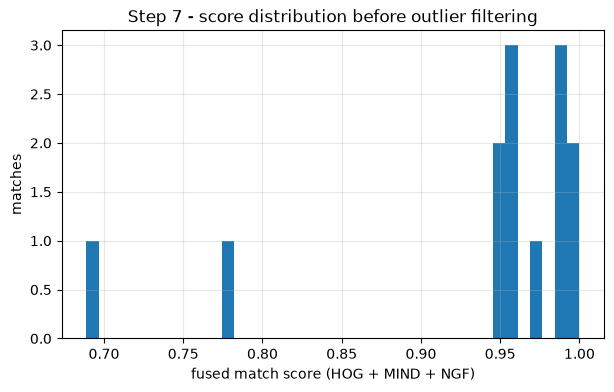

In [15]:
all_matches = matching.match_patches(
    proc_Ih=scaled_proc_Ih, histo_mask=scaled_proc_Mh,
    slab_Im=slab_Im, slab_Mm=slab_Mm,
    z_min=z_min, z_max=z_max,
    hist_patch=best_patch, hist_stride=best_hist_stride,
    mri_patch=best_patch, mri_stride=best_mri_stride,
    w_ngf=FINE_MATCH_W_NGF,
    **matcher,
)
scores_all = np.array([m["score"] for m in all_matches["matches"]], dtype=np.float32)
finite = scores_all[np.isfinite(scores_all)]
print(f"{len(all_matches['matches'])} matches, {len(finite)} with a finite score")
print(f"score: min={finite.min():.4f} median={np.median(finite):.4f} max={finite.max():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(finite, bins=40)
ax.set_xlabel("fused match score (HOG + MIND + NGF)")
ax.set_ylabel("matches")
ax.set_title("Step 7 - score distribution before outlier filtering")
ax.grid(alpha=0.3)
plt.show()

## Step 8. Outlier filtering

`outliers.filter_outliers` removes wrong matches in two stages: a coarse RANSAC plane fit
through the MRI match centres (threshold `outlier_plane_dist` of the profile), then a stricter
kNN / IQR cleanup with a connected-component test (`outlier_knn`).

In [16]:
clean_matches, coarse_matches, pts_clean, sc_clean = outliers.filter_outliers(
    all_matches=all_matches["matches"], z_min=z_min, z_max=z_max,
    plane_dist_thresh=settings["outlier_plane_dist"], knn_params=settings["outlier_knn"],
)
print(f"all    : {len(all_matches['matches'])}")
print(f"coarse : {len(coarse_matches)}  (RANSAC plane)")
print(f"clean  : {len(clean_matches)}  (kNN / IQR)")
print(f"clean MRI z range: {pts_clean[:, 0].min():.1f} .. {pts_clean[:, 0].max():.1f}")

INFO histo2mri.outliers: Outlier filter: removed 2, kept 10 matches


all    : 18
coarse : 12  (RANSAC plane)
clean  : 10  (kNN / IQR)
clean MRI z range: 248.0 .. 253.0


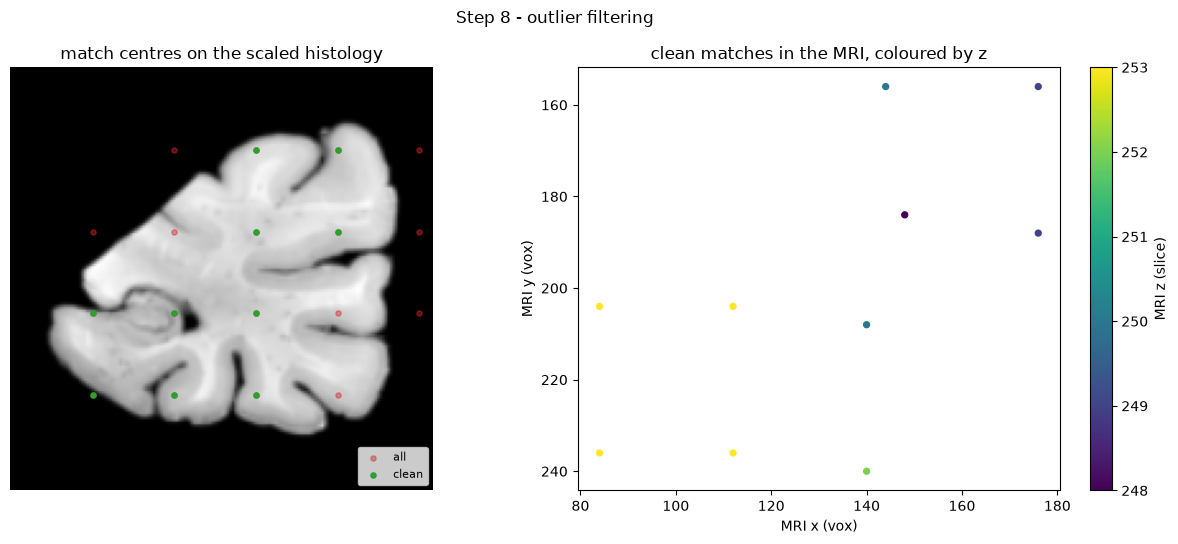

In [17]:
# Where the surviving matches sit: histology centres (left) and their MRI position (right).
h_all = np.array([m["hist_center_yx"] for m in all_matches["matches"]], dtype=np.float32)
h_clean = np.array([m["hist_center_yx"] for m in clean_matches], dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].imshow(as_2d(scaled_proc_Ih), cmap="gray")
axes[0].scatter(h_all[:, 1], h_all[:, 0], s=14, c="tab:red", alpha=0.45, label="all")
axes[0].scatter(h_clean[:, 1], h_clean[:, 0], s=14, c="tab:green", label="clean")
axes[0].set_title("match centres on the scaled histology")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].axis("off")

sc = axes[1].scatter(pts_clean[:, 2], pts_clean[:, 1], c=pts_clean[:, 0], s=18, cmap="viridis")
axes[1].set_xlabel("MRI x (vox)")
axes[1].set_ylabel("MRI y (vox)")
axes[1].set_title("clean matches in the MRI, coloured by z")
axes[1].invert_yaxis()
fig.colorbar(sc, ax=axes[1], label="MRI z (slice)")
fig.suptitle("Step 8 - outlier filtering")
fig.tight_layout()
plt.show()

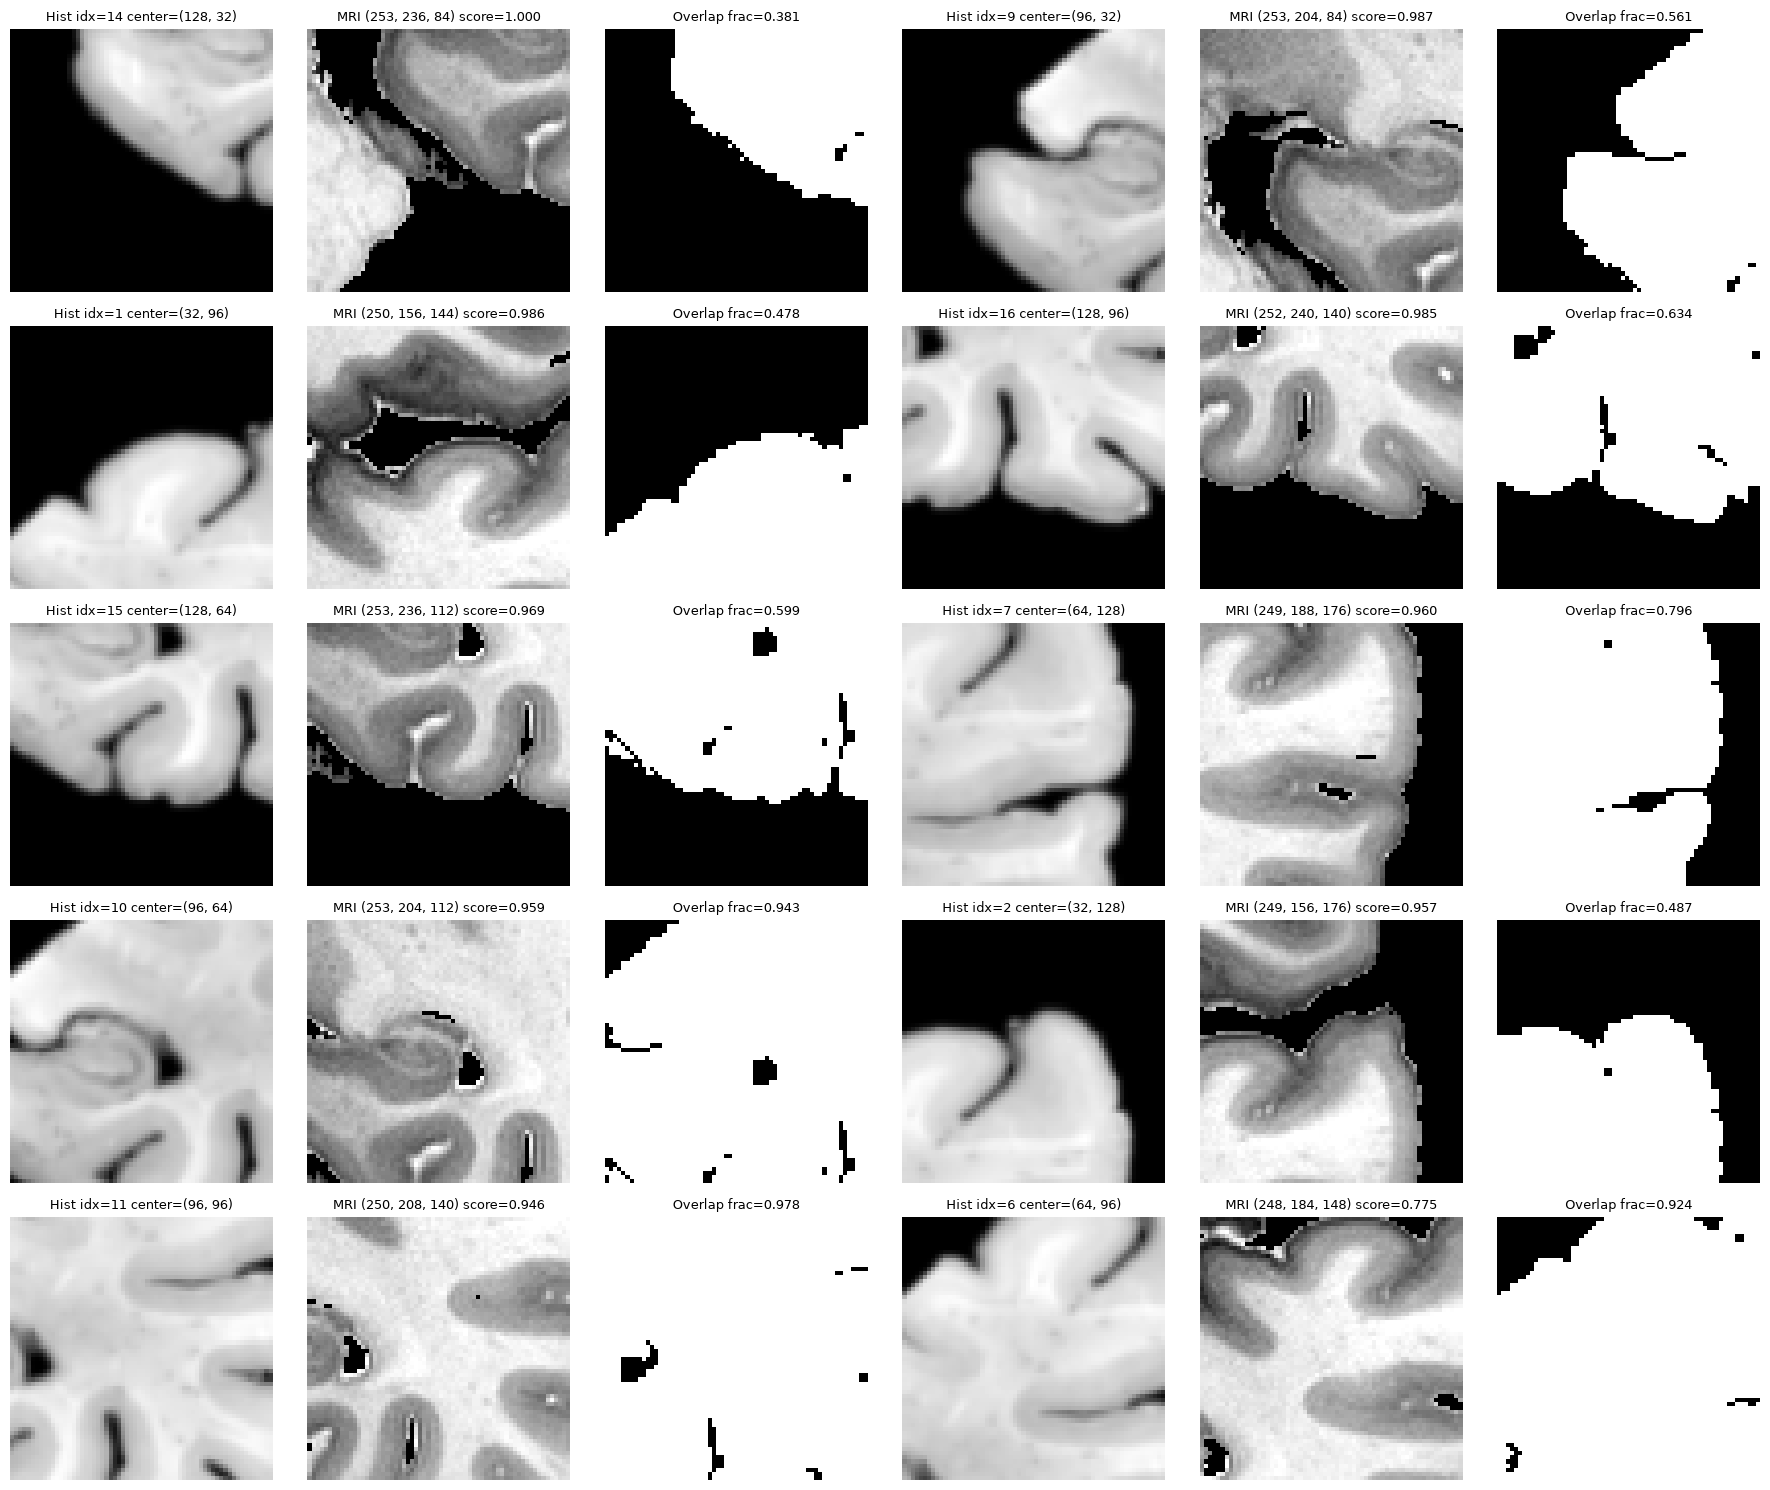

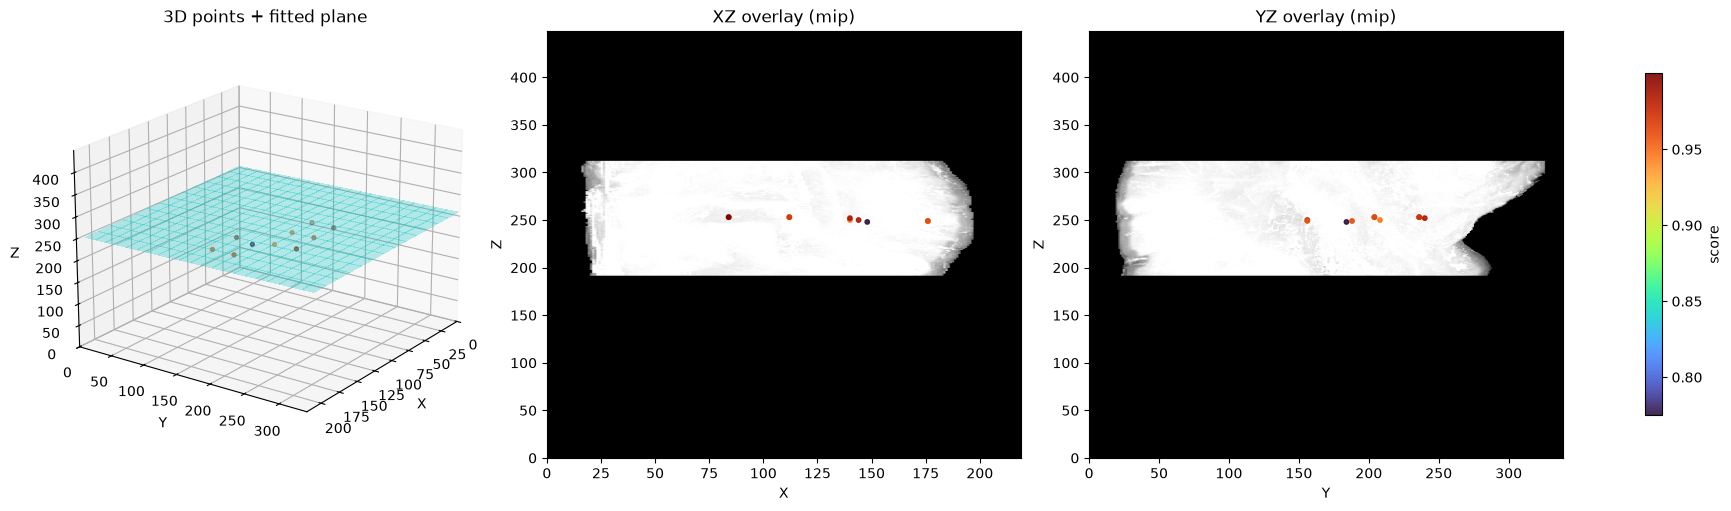

{'a': -0.03742713381405112,
 'b': 0.017105169289654665,
 'c': 252.71696045710405,
 'n_points': 10}

In [18]:
# The pipeline's own ROI QC figures (saved per section with --save-roi-qc).
qc.show_matched_pairs(
    clean_matches, all_matches["hist_img"], all_matches["mri_img"],
    patch=best_patch, ncols=2, save_file=out_file("roi_pairs.png"),
    hist_mask=all_matches["hist_mask"], mri_mask=all_matches["mri_mask"],
)
qc.visualize_roi_from_matches(
    matches=clean_matches, mri_vol=slab_Im, z_min=z_min, z_max=z_max, mode="mip",
    save_file=out_file("roi_3d.png"),
)

## Step 9. ROI plane

`canvas.extract_roi_plane` fits a plane through the clean MRI match centres and samples the MRI
on it. This is not only QC: the plane image sets the size of the common canvas, and its origin
`(x0, y0)` sets the (u, v) frame of the global plane G.

plane image (173, 181), MRI voxel bounds x 40..220, y 112..284
NaN fraction (plane leaving the slab in z): 0.0000


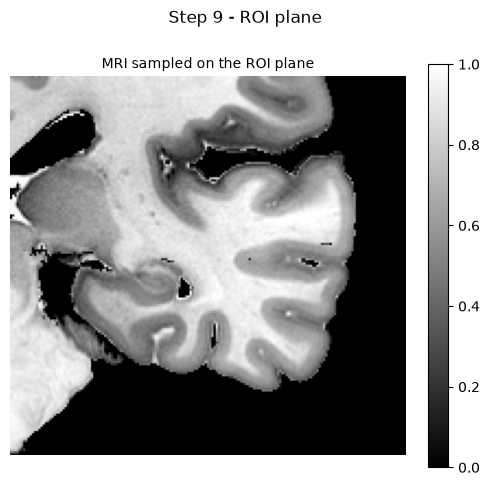

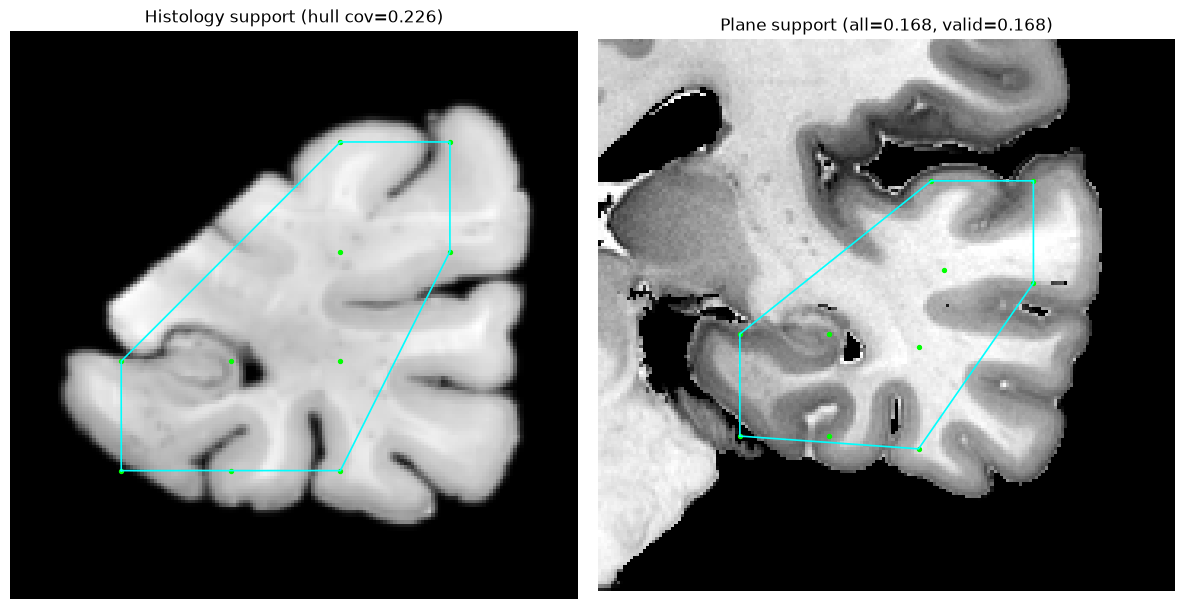

In [19]:
plane_img, x0, x1, y0, y1 = canvas.extract_roi_plane(clean_matches, pts_clean, slab_Im, device)
print(f"plane image {plane_img.shape}, MRI voxel bounds x {x0}..{x1}, y {y0}..{y1}")
print(f"NaN fraction (plane leaving the slab in z): {np.isnan(plane_img).mean():.4f}")

show(np.nan_to_num(plane_img), ["MRI sampled on the ROI plane"], suptitle="Step 9 - ROI plane")
qc.plot_roi_support(clean_matches, scaled_proc_Ih, plane_img, x0, y0,
                    save_file=out_file("roi_support.png"))

## Step 10. Common canvas

`canvas.create_common_canvas` centres the scaled histology and the ROI plane image on one
shared grid. From here on, one canvas pixel equals one MRI voxel in-plane, and the offsets
`(oy_h, ox_h)` relate canvas pixels to histology pixels.

The checkerboard below still shows the two images *unregistered*: only the canvas is shared,
no transform has been applied yet.

canvas 173 x 181; histology offset (oy, ox) = (3, 7); MRI plane offset = (0, 0)


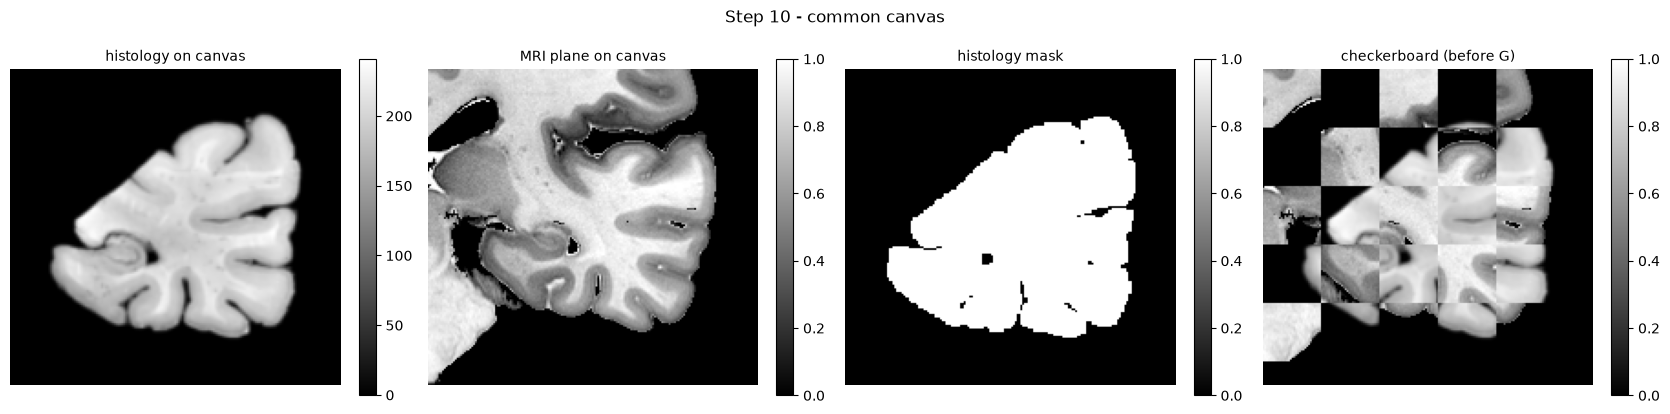

In [20]:
(Hc, Wc, oy_h, ox_h, oy_m, ox_m,
 hist_common, mri_common, mask_common) = canvas.create_common_canvas(
    scaled_proc_Ih, scaled_proc_Mh, plane_img
)
print(f"canvas {Hc} x {Wc}; histology offset (oy, ox) = ({oy_h}, {ox_h}); "
      f"MRI plane offset = ({oy_m}, {ox_m})")

checker = qc.make_checkerboard(np.nan_to_num(hist_common), np.nan_to_num(mri_common), tile_size=32)
show([hist_common, mri_common, mask_common, checker],
     ["histology on canvas", "MRI plane on canvas", "histology mask", "checkerboard (before G)"],
     size=4.2, suptitle="Step 10 - common canvas")

## Step 11. Global in-plane transform G

`plane.fit_global_plane` fits the plane `z = a*x + b*y + c` in the MRI together with the 2D
similarity that places the histology on it. G is the backbone of the surface: everything after
this is a residual on top of G.

In [21]:
# MRI x/y range covered by the whole canvas (1 canvas pixel = 1 MRI voxel), so that G's (u, v)
# equal canvas (column, row).
step = 1.0
x_range_final = (x0 - ox_m * step, x0 + (Wc - 1 - ox_m) * step)
y_range_final = (y0 - oy_m * step, y0 + (Hc - 1 - oy_m) * step)

clean_matches_common = plane.matches_to_common_canvas(
    clean_matches=clean_matches, oy_h=oy_h, ox_h=ox_h)

# Bounds for fit_global_plane's MRI filter, taken from the matches themselves.
yy = np.array([m["mri_center_zyx"][1] for m in clean_matches_common], np.float32)
xx = np.array([m["mri_center_zyx"][2] for m in clean_matches_common], np.float32)
Hm_fit = int(np.ceil(yy.max())) + 1
Wm_fit = int(np.ceil(xx.max())) + 1

G = plane.fit_global_plane(
    clean_matches_common, x_range_final, y_range_final,
    mri_hw=(Hm_fit, Wm_fit), hist_hw=(Hc, Wc), robust=True,
)
print("G origin X0 (MRI vox x, y, z):", np.round(G["X0"], 3))
print("G in-plane axes e1, e2       :", np.round(G["e1"], 5), np.round(G["e2"], 5))
print("G normal n                   :", np.round(G["n"], 5))

G origin X0 (MRI vox x, y, z): [ 40.    112.    252.931]
G in-plane axes e1, e2       : [ 1.       0.      -0.04047] [0.      1.      0.01992]
G normal n                   : [ 0.04043 -0.0199   0.99898]


In [22]:
# Histology image and mask on the common canvas as (1, Hc, Wc) sitk images.
proc_Ih_common_arr = hist_common.astype(np.float32)[None, ...]
proc_Ih_common_sitk = sitk.GetImageFromArray(proc_Ih_common_arr)
proc_Mh_common_arr = mask_common.astype(np.float32)[None, ...]
proc_Mh_common_sitk = sitk.GetImageFromArray(proc_Mh_common_arr)
print("histology on canvas as sitk:", proc_Ih_common_sitk.GetSize())

histology on canvas as sitk: (181, 173, 1)


## Step 12. Robust TPS: RANSAC, MAD and the in-plane filter

Three rejection passes on the clean matches:

1. a MAD-rejecting TPS fit, only to derive an adaptive RANSAC inlier threshold from its
   residuals (median + 3 sigma, clipped to 3..20 voxels);
2. `fit_tps_robust(method="ransac")` with that threshold, then a second MAD pass on its inliers;
3. an in-plane distance filter against G: a flexible TPS absorbs bad matches, G does not, so
   matches further than `INPLANE_MAX` voxels in-plane from `G(u, v)` are dropped.

A section with only a handful of matches cannot reach the RANSAC stage's `min_inliers=30`, so
it logs `no valid hypothesis found; falling back to all points` and the MAD refit does the
robust fitting. That is expected on sparse sections, not a failure.

In [23]:
# Adaptive RANSAC inlier threshold from the residuals of a MAD fit.
_tps_diag, _, _, _, _resid_diag, _ = tps.fit_tps_robust(
    clean_matches_common, G, method="mad",
    mad_thresh=2.5, mad_iterations=3, lam_hyp=1e-2, lam_final=1e-2,
    device=device, normalize_uv=False,
)
_r = _resid_diag.cpu().numpy()
_med = float(np.median(_r))
_scale = 1.4826 * float(np.median(np.abs(_r - _med))) + 1e-8
adaptive_thresh = float(np.clip(_med + 3.0 * _scale, 3.0, 20.0))
print(f"residuals: median={_med:.2f} vox, robust sigma={_scale:.2f} vox "
      f"-> adaptive inlier threshold {adaptive_thresh:.2f} vox")

residuals: median=0.00 vox, robust sigma=0.00 vox -> adaptive inlier threshold 3.00 vox


In [24]:
tps_ransac, uv_in, xyz_in, inlier_mask, _, score = tps.fit_tps_robust(
    clean_matches_common, G, method="ransac",
    n_iters=300, sample_size=RANSAC_SAMPLE_SIZE, inlier_thresh=adaptive_thresh, min_inliers=30,
    device=device, normalize_uv=False, lam_hyp=1e-2, lam_final=1e-2,
)
if len(inlier_mask) != len(clean_matches_common):
    raise RuntimeError("TPS inlier mask does not line up with the match list")
matches_inliers = [m for m, keep in zip(clean_matches_common, inlier_mask.cpu().tolist()) if keep]
print(f"RANSAC (sample_size={RANSAC_SAMPLE_SIZE}): "
      f"{len(matches_inliers)}/{len(clean_matches_common)} inliers")

# Second MAD pass on the RANSAC inliers.
tps_init_final, uv_in2, xyz_in2, inlier_mask2, _, score2 = tps.fit_tps_robust(
    matches_inliers, G, method="mad",
    mad_thresh=2.5, mad_iterations=2, lam_hyp=1e-2, lam_final=1e-2,
    device=device, normalize_uv=False,
)
if len(inlier_mask2) != len(matches_inliers):
    raise RuntimeError("TPS inlier mask does not line up with the match list")
matches_inliers_final = [m for m, keep in zip(matches_inliers, inlier_mask2.cpu().tolist()) if keep]
print(f"MAD refit: {len(matches_inliers_final)}/{len(matches_inliers)} kept")

hist_xy_in2 = np.asarray(
    [[float(m["hist_center_yx"][1]), float(m["hist_center_yx"][0])] for m in matches_inliers_final],
    dtype=np.float32,
)

WARNING histo2mri.tps: RANSAC TPS: no valid hypothesis found; falling back to all points.


RANSAC (sample_size=3): 10/10 inliers
MAD refit: 8/10 kept


in-plane filter: kept 8/8 (max in-plane 4.4 vox)


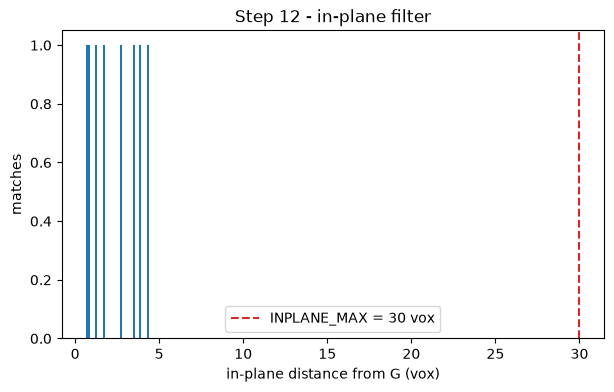

In [25]:
# In-plane filter against G (INPLANE_MAX is written inline in pipeline._register).
INPLANE_MAX = 30.0   # vox
_X0 = np.asarray(G["X0"], np.float32); _e1 = np.asarray(G["e1"], np.float32)
_e2 = np.asarray(G["e2"], np.float32); _n = np.asarray(G["n"], np.float32)
_uvn = uv_in2.detach().cpu().numpy() if torch.is_tensor(uv_in2) else np.asarray(uv_in2)
_xyzn = xyz_in2.detach().cpu().numpy() if torch.is_tensor(xyz_in2) else np.asarray(xyz_in2)
_res = _xyzn - (_X0[None] + _uvn[:, 0:1] * _e1[None] + _uvn[:, 1:2] * _e2[None])
_inp = np.linalg.norm(_res - (_res @ _n)[:, None] * _n[None, :], axis=1)
_keep = _inp <= INPLANE_MAX
_km = torch.as_tensor(_keep, device=uv_in2.device) if torch.is_tensor(uv_in2) else _keep
uv_in2 = uv_in2[_km]
xyz_in2 = xyz_in2[_km]
hist_xy_in2 = np.asarray(hist_xy_in2)[_keep]
matches_inliers_final = [m for m, k in zip(matches_inliers_final, _keep.tolist()) if k]
print(f"in-plane filter: kept {int(_keep.sum())}/{len(_keep)} "
      f"(max in-plane {_inp.max():.1f} vox)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(_inp, bins=30)
ax.axvline(INPLANE_MAX, color="tab:red", ls="--", label=f"INPLANE_MAX = {INPLANE_MAX:g} vox")
ax.set_xlabel("in-plane distance from G (vox)")
ax.set_ylabel("matches")
ax.set_title("Step 12 - in-plane filter")
ax.legend()
plt.show()

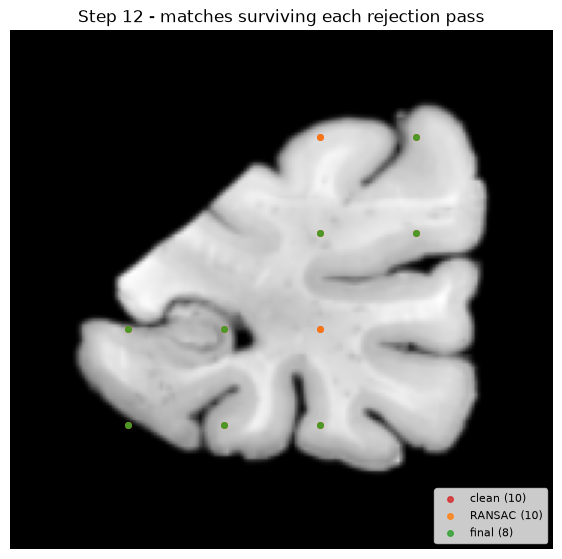

In [26]:
# Which matches survived each pass, on the common canvas.
def _centres(ms):
    return np.array([m["hist_center_yx"] for m in ms], dtype=np.float32)


fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(hist_common, cmap="gray")
for ms, colour, label in [
        (clean_matches_common, "tab:red", f"clean ({len(clean_matches_common)})"),
        (matches_inliers, "tab:orange", f"RANSAC ({len(matches_inliers)})"),
        (matches_inliers_final, "tab:green", f"final ({len(matches_inliers_final)})")]:
    c = _centres(ms)
    if len(c):
        ax.scatter(c[:, 1], c[:, 0], s=16, c=colour, label=label, alpha=0.8)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Step 12 - matches surviving each rejection pass")
ax.axis("off")
plt.show()

## Step 13. Residual TPS on top of G

Two residual splines, both with zero-residual anchors on a grid far from the matches, so that
the surface falls back to G where there is no support:

- `fit_residual_tps3d`: the MRI xyz offset from `G(u, v)` - the out-of-plane curvature;
- `fit_residual_tps2d`: the histology xy offset from G's similarity - the in-plane distortion.

`clamp_vox` caps how far the initial surface may leave G (1.25 x the 99th percentile of the
kept matches' displacement, clipped to 8..60 voxels).

In [27]:
tps3d_res, uv_all_3d, dxyz_all, uv_anchor_3d = tps.fit_residual_tps3d(
    uv_ctrl=uv_in2, xyz_ctrl=xyz_in2, G=G, device=device, lam=1e-1,
    normalize_uv=False, anchor_step=24.0, far_thr=35.0, max_anchors=1200, seed=42,
)
tps2d_res, uv_all_2d, dxy_all, uv_anchor_2d = tps.fit_residual_tps2d(
    uv_ctrl=uv_in2, hist_xy_ctrl=hist_xy_in2, G=G, device=device, lam=2e-1,
    normalize_uv=False, anchor_step=24.0, far_thr=35.0, max_anchors=1200, seed=42,
)

_uvn2 = uv_in2.detach().cpu().numpy() if torch.is_tensor(uv_in2) else np.asarray(uv_in2)
_xyzn2 = xyz_in2.detach().cpu().numpy() if torch.is_tensor(xyz_in2) else np.asarray(xyz_in2)
_dxyz = _xyzn2 - (_X0[None] + _uvn2[:, 0:1] * _e1[None] + _uvn2[:, 1:2] * _e2[None])
_mag = np.linalg.norm(_dxyz, axis=1)
clamp_vox = float(np.clip(1.25 * np.percentile(_mag, 99), 8.0, 60.0))
print(f"control points: {len(_uvn2)}, anchors 3D: {len(uv_anchor_3d)}, 2D: {len(uv_anchor_2d)}")
print(f"|xyz - G(u,v)|: median={np.median(_mag):.1f} p99={np.percentile(_mag, 99):.1f} "
      f"max={_mag.max():.1f} vox  ->  clamp_vox={clamp_vox:.2f}")

control points: 8, anchors 3D: 35, 2D: 35
|xyz - G(u,v)|: median=2.3 p99=4.5 max=4.6 vox  ->  clamp_vox=8.00


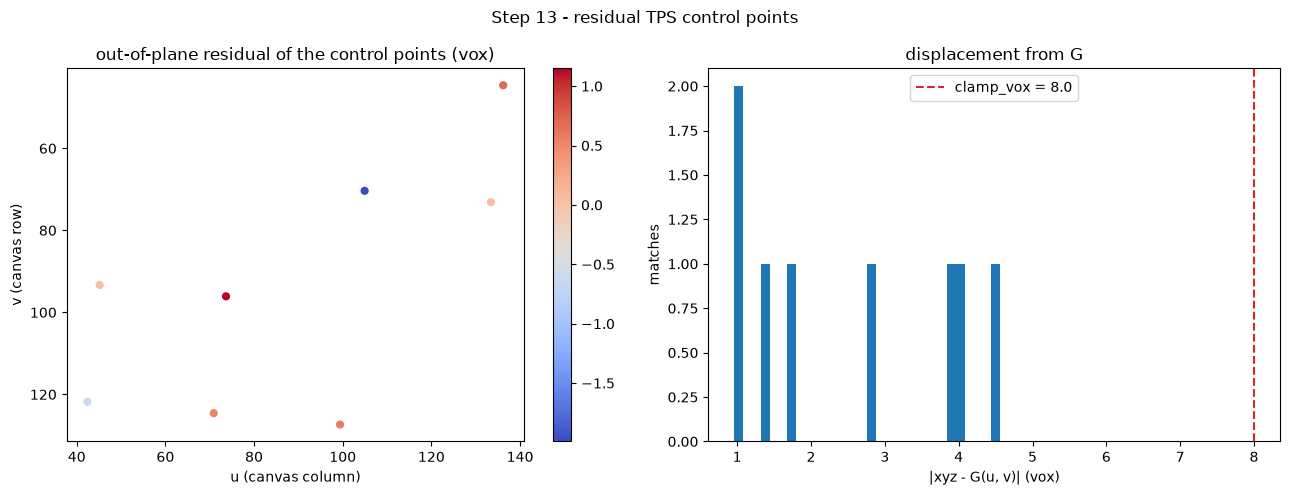

In [28]:
# How far the control points pull the surface off G, and in which direction.
_offplane = _dxyz @ _n

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
s = axes[0].scatter(_uvn2[:, 0], _uvn2[:, 1], c=_offplane, s=24, cmap="coolwarm")
axes[0].set_xlabel("u (canvas column)")
axes[0].set_ylabel("v (canvas row)")
axes[0].set_title("out-of-plane residual of the control points (vox)")
axes[0].invert_yaxis()
fig.colorbar(s, ax=axes[0])
axes[1].hist(_mag, bins=30)
axes[1].axvline(clamp_vox, color="tab:red", ls="--", label=f"clamp_vox = {clamp_vox:.1f}")
axes[1].set_xlabel("|xyz - G(u, v)| (vox)")
axes[1].set_ylabel("matches")
axes[1].set_title("displacement from G")
axes[1].legend()
fig.suptitle("Step 13 - residual TPS control points")
fig.tight_layout()
plt.show()

## Step 14. Histology on the initial surface

`tps.resample_histology_on_surface` looks up, for every canvas pixel, the histology position
given by G plus the confidence-weighted 2D residual. `conf_hist` is the support confidence (how
close that pixel is to a control point) and `valid_hist` marks lookups that land inside the
histology image. The resulting image is the target the refinement drives the MRI towards.

valid histology lookups: 0.792 of the canvas
inside the tissue mask : 0.296 of the canvas


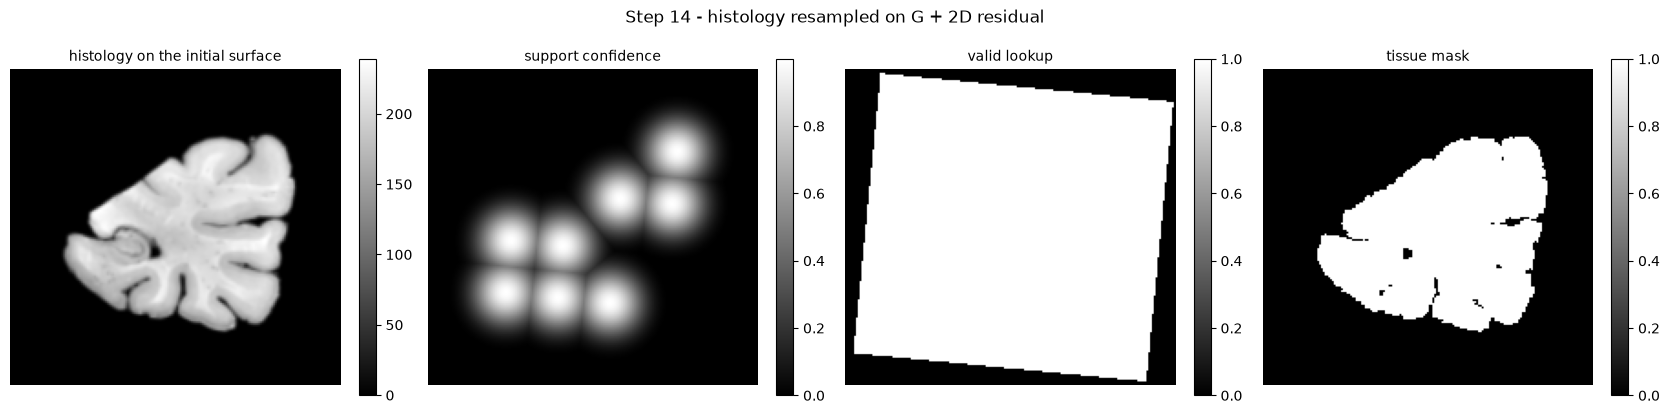

In [29]:
(hist_on_init_tps, valid_hist, uv_map_sym, xy_map_sym,
 conf_hist, dmin_hist) = tps.resample_histology_on_surface(
    hist_img=proc_Ih_common_sitk, G=G, tps2d_residual=tps2d_res, ctrl_uv=uv_in2,
    canvas_shape=(Hc, Wc), device=device, is_mask=False, sigma_uv=20.0, min_conf=0.25,
    hard_mult=2.0, max_residual_px=20.0, return_extra=True,
)
hist_mask_on_init_tps = tps.resample_histology_on_surface(
    hist_img=proc_Mh_common_sitk, G=G, tps2d_residual=tps2d_res, ctrl_uv=uv_in2,
    canvas_shape=(Hc, Wc), device=device, is_mask=True, sigma_uv=20.0, min_conf=0.25,
    hard_mult=2.0, max_residual_px=20.0, return_extra=False,
)
hist_mask_on_init_tps = (hist_mask_on_init_tps > 0.5)
print(f"valid histology lookups: {np.asarray(valid_hist).mean():.3f} of the canvas")
print(f"inside the tissue mask : {np.asarray(hist_mask_on_init_tps).mean():.3f} of the canvas")

show([hist_on_init_tps, conf_hist, valid_hist, hist_mask_on_init_tps],
     ["histology on the initial surface", "support confidence", "valid lookup", "tissue mask"],
     size=4.2, suptitle="Step 14 - histology resampled on G + 2D residual")

## Step 15. Fold check of the initial sheet

Where neighbouring matches disagree, the in-plane part of the 3D residual can fold the sheet,
and the refinement keeps such folds (they show up as swirls in the MRI on the histology). The
pipeline measures the folded fraction of the sheet the refinement would start from; if it is
above zero, it builds an alternative with the in-plane part scaled down by
`FOLD_FIX_INPLANE_SCALES` and refines that one as well (step 16).

In [30]:
dims_xyz = slab_Im.GetSize()
uv_canvas, _, _ = refine.prepare_coords_from_G_canvas(
    G, Hc, Wc, device, common_shift_yx=G.get("canvas_offset_yx", None))


def initial_folding(residual):
    # Folded percentage of the sheet the refinement would start from, for a 3D residual.
    sheet = tps.ResidualToGSurface3D(G=G, residual_tps=residual, device=device).to(device)
    xyz = refine.tps_sheet_xyz_norm(sheet, G, uv_canvas, Hc, Wc, *dims_xyz, device,
                                    ctrl_uv=uv_in2, sigma_uv=20.0, min_conf=0.25,
                                    max_disp_vox=clamp_vox)
    inside = ((xyz >= 0) & (xyz <= 1)).all(dim=-1).detach().cpu().numpy()
    return refine.sheet_folding_pct(xyz, inside & valid_hist & hist_mask_on_init_tps, dims_xyz, G)


fold_initial = initial_folding(tps3d_res)
tps3d_res_shrunk = None
inplane_scale = None
if fold_initial > 0.0:
    for inplane_scale in FOLD_FIX_INPLANE_SCALES:
        tps3d_res_shrunk = tps.InplaneScaledResidual(tps3d_res, G["n"], inplane_scale)
        fold_shrunk = initial_folding(tps3d_res_shrunk)
        if fold_shrunk <= 0.0:
            break
    print(f"initial sheet folds on {fold_initial:.3f}% of the canvas; "
          f"in-plane residual x{inplane_scale:g}: {fold_shrunk:.3f}%")
else:
    print(f"initial sheet does not fold ({fold_initial:.3f}%); no fold fix needed")

initial sheet does not fold (0.000%); no fold fix needed


## Step 16. Curved-sheet refinement

`refine.refine_curved_sheet` starts from G plus the 3D residual, warm-starts a B-spline residual
from the matches, and optimises the sheet on three pyramid levels so that the MRI sampled on it
matches the histology of step 14. The image loss is SSIM and/or MIND according to the profile;
`LAM_AREA` and `LAM_SHAPE` keep the sheet locally rigid.

This is the longest step. If the initial sheet folded, the scaled-down alternative is refined as
well and the less folded result is kept.

In [31]:
def run_refinement(residual):
    # Refine one initial surface; returns (init_tps_abs, refined, folded_pct).
    init_tps_abs = tps.ResidualToGSurface3D(G=G, residual_tps=residual, device=device).to(device)
    refined = refine.refine_curved_sheet(
        slab_Im=slab_Im, slab_Mm=slab_Mm, init_G=G, init_tps=init_tps_abs,
        matches_for_warmstart=matches_inliers_final, device=device,
        hist_on_init_tps=hist_on_init_tps, hist_mask_on_init_tps=None,
        ctrl_uv_support=uv_in2, tps_sigma_uv=20.0, tps_min_conf=0.25,
        tps_max_disp_vox=clamp_vox,
        lam_area=LAM_AREA, lam_shape=LAM_SHAPE, w_rigid_mode=W_RIGID_MODE,
        similarity_weights=settings["refine_similarity_weights"],
        gif_file=None,
    )
    valid = refined[2] & valid_hist & hist_mask_on_init_tps
    return init_tps_abs, refined, refine.sheet_folding_pct(refined[0], valid, dims_xyz, G)


t0 = time.perf_counter()
init_tps_abs, refined, fold_final = run_refinement(tps3d_res)
print(f"refinement took {time.perf_counter() - t0:.1f}s, final folding {fold_final:.3f}%")

if tps3d_res_shrunk is not None:
    result_shrunk = run_refinement(tps3d_res_shrunk)
    use_shrunk = result_shrunk[2] < fold_final
    print(f"fold fix: original {fold_final:.3f}%, in-plane x{inplane_scale:g} "
          f"{result_shrunk[2]:.3f}% -> "
          f"{'using the scaled residual' if use_shrunk else 'keeping the original'}")
    if use_shrunk:
        init_tps_abs, refined, fold_final = result_shrunk
    del result_shrunk

(xyz_norm_final, mri_on_final_sheet, valid_mri,
 xyz_norm_base, conf, phi, n0, alpha, rf_psi, rf_beta) = refined
print("refined sheet:", tuple(xyz_norm_final.shape))

refinement took 17.8s, final folding 0.000%
refined sheet: (173, 181, 3)


valid sheet pixels: 0.296 of the canvas


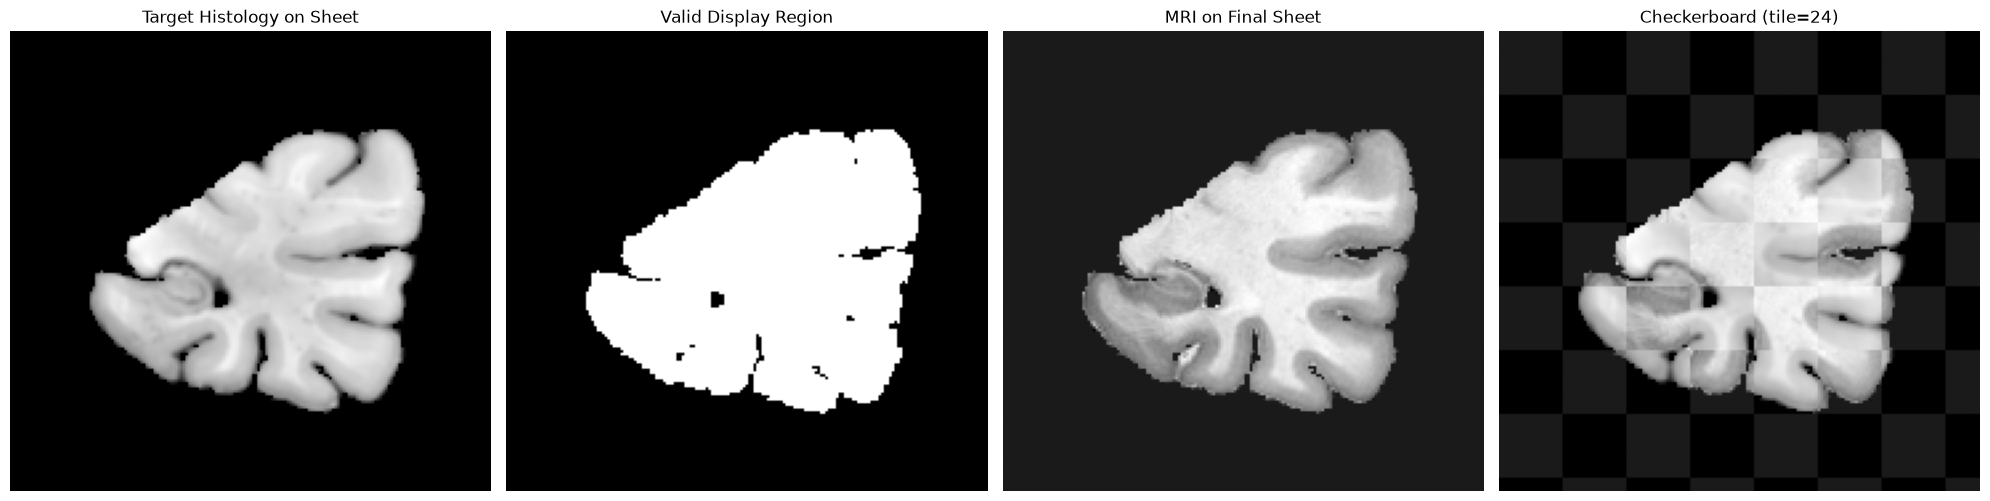

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(173, 181), dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(173, 181), dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(173, 181), dtype=float32),
 array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False

In [32]:
# QC in sheet space: the histology target against the MRI sampled on the refined sheet.
valid_display = valid_mri & valid_hist & hist_mask_on_init_tps
print(f"valid sheet pixels: {valid_display.mean():.3f} of the canvas")

qc.plot_mri_on_sheet(
    hist_on_init_tps=hist_on_init_tps, valid_display=valid_display,
    mri_on_final_sheet=mri_on_final_sheet,
    save_file=out_file("histo_in_mri_space_all.png"),
)

displacement inside the valid region: median=3.01 vox, p95=6.21 vox, max=10.29 vox


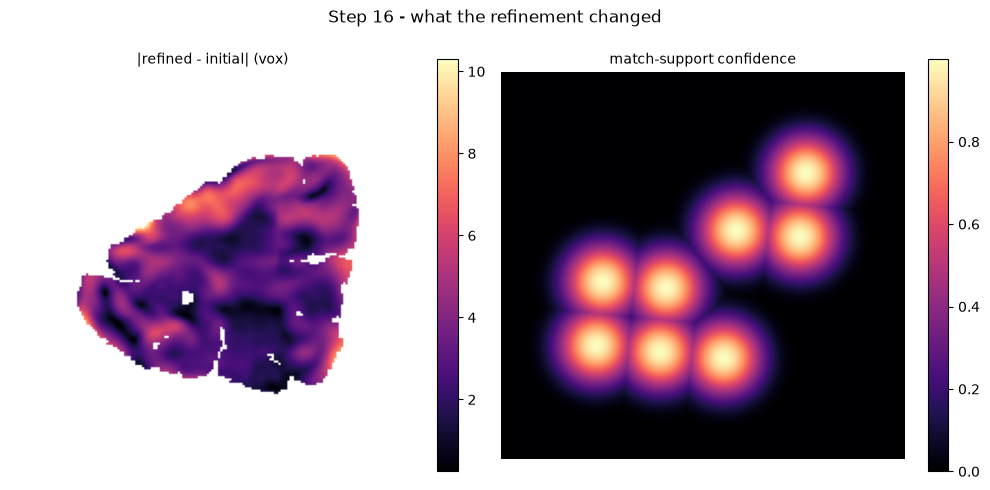

In [33]:
# How far the refinement moved the sheet away from the initial surface, in voxels.
_dims = np.asarray(dims_xyz, dtype=np.float32) - 1.0
_base = xyz_norm_base.detach().cpu().numpy() * _dims
_final = xyz_norm_final.detach().cpu().numpy() * _dims
_disp = np.linalg.norm(_final - _base, axis=-1)
_disp_masked = np.where(valid_display, _disp, np.nan)
print(f"displacement inside the valid region: median={np.nanmedian(_disp_masked):.2f} vox, "
      f"p95={np.nanpercentile(_disp_masked, 95):.2f} vox, max={np.nanmax(_disp_masked):.2f} vox")

show([_disp_masked, as_2d(conf)],
     ["|refined - initial| (vox)", "match-support confidence"],
     cmap="magma", suptitle="Step 16 - what the refinement changed")

## Step 17. Where the section sits in the volume

`qc.plot_histology_in_mri_space` draws the refined sheet as a point cloud at its MRI voxel
positions, coloured by the histology sampled on it, and the MRI slice nearest the sheet's
centre along each axis with the sheet drawn on it. This is the histology placed in MRI space,
and the same geometry a 3D viewer would be given.

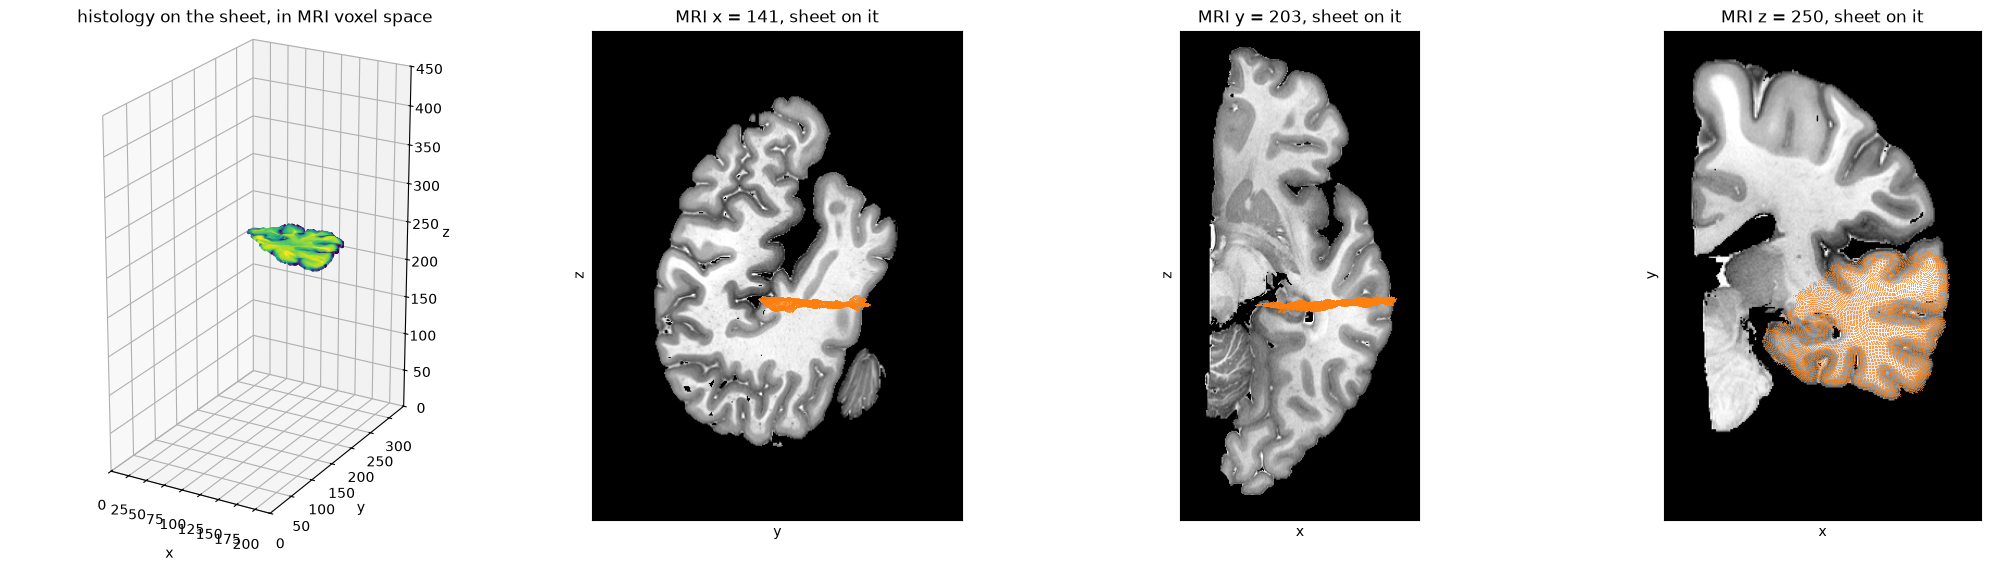

In [34]:
qc.plot_histology_in_mri_space(
    xyz_norm_final=xyz_norm_final.detach().cpu().numpy(),
    valid_surf=valid_display,
    histo_on_surface=np.asarray(hist_on_init_tps),
    mri_zyx=sitk.GetArrayFromImage(slab_Im),
    mri_size=slab_Im.GetSize(),
    save_file=out_file("histo_in_mri_volume.png"),
)

## Step 18. Back to HR histology space

`inverse.mri_on_histology_space` composes the affine chain HR histology -> common canvas, builds
the target validity mask and resamples the MRI through the refined sheet onto the
full-resolution histology grid. This is the QC that shows the registration at the histology's
own resolution, and the memory peak of the whole pipeline.

In [35]:
A_hr_to_common, A_common_to_hr = inverse.build_hr_common_affines(
    proc_Ih, scaled_proc_Ih, A_hr_to_proc, oy_h, ox_h
)
print("A_common_to_hr =\n", np.round(A_common_to_hr, 4))

A_common_to_hr =
 [[ 7.7108400e+01  0.0000000e+00  0.0000000e+00 -1.5512048e+03]
 [ 0.0000000e+00  7.7108400e+01  0.0000000e+00 -1.7427711e+03]
 [ 0.0000000e+00  0.0000000e+00  1.0000000e+02  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  1.0000000e+00]]


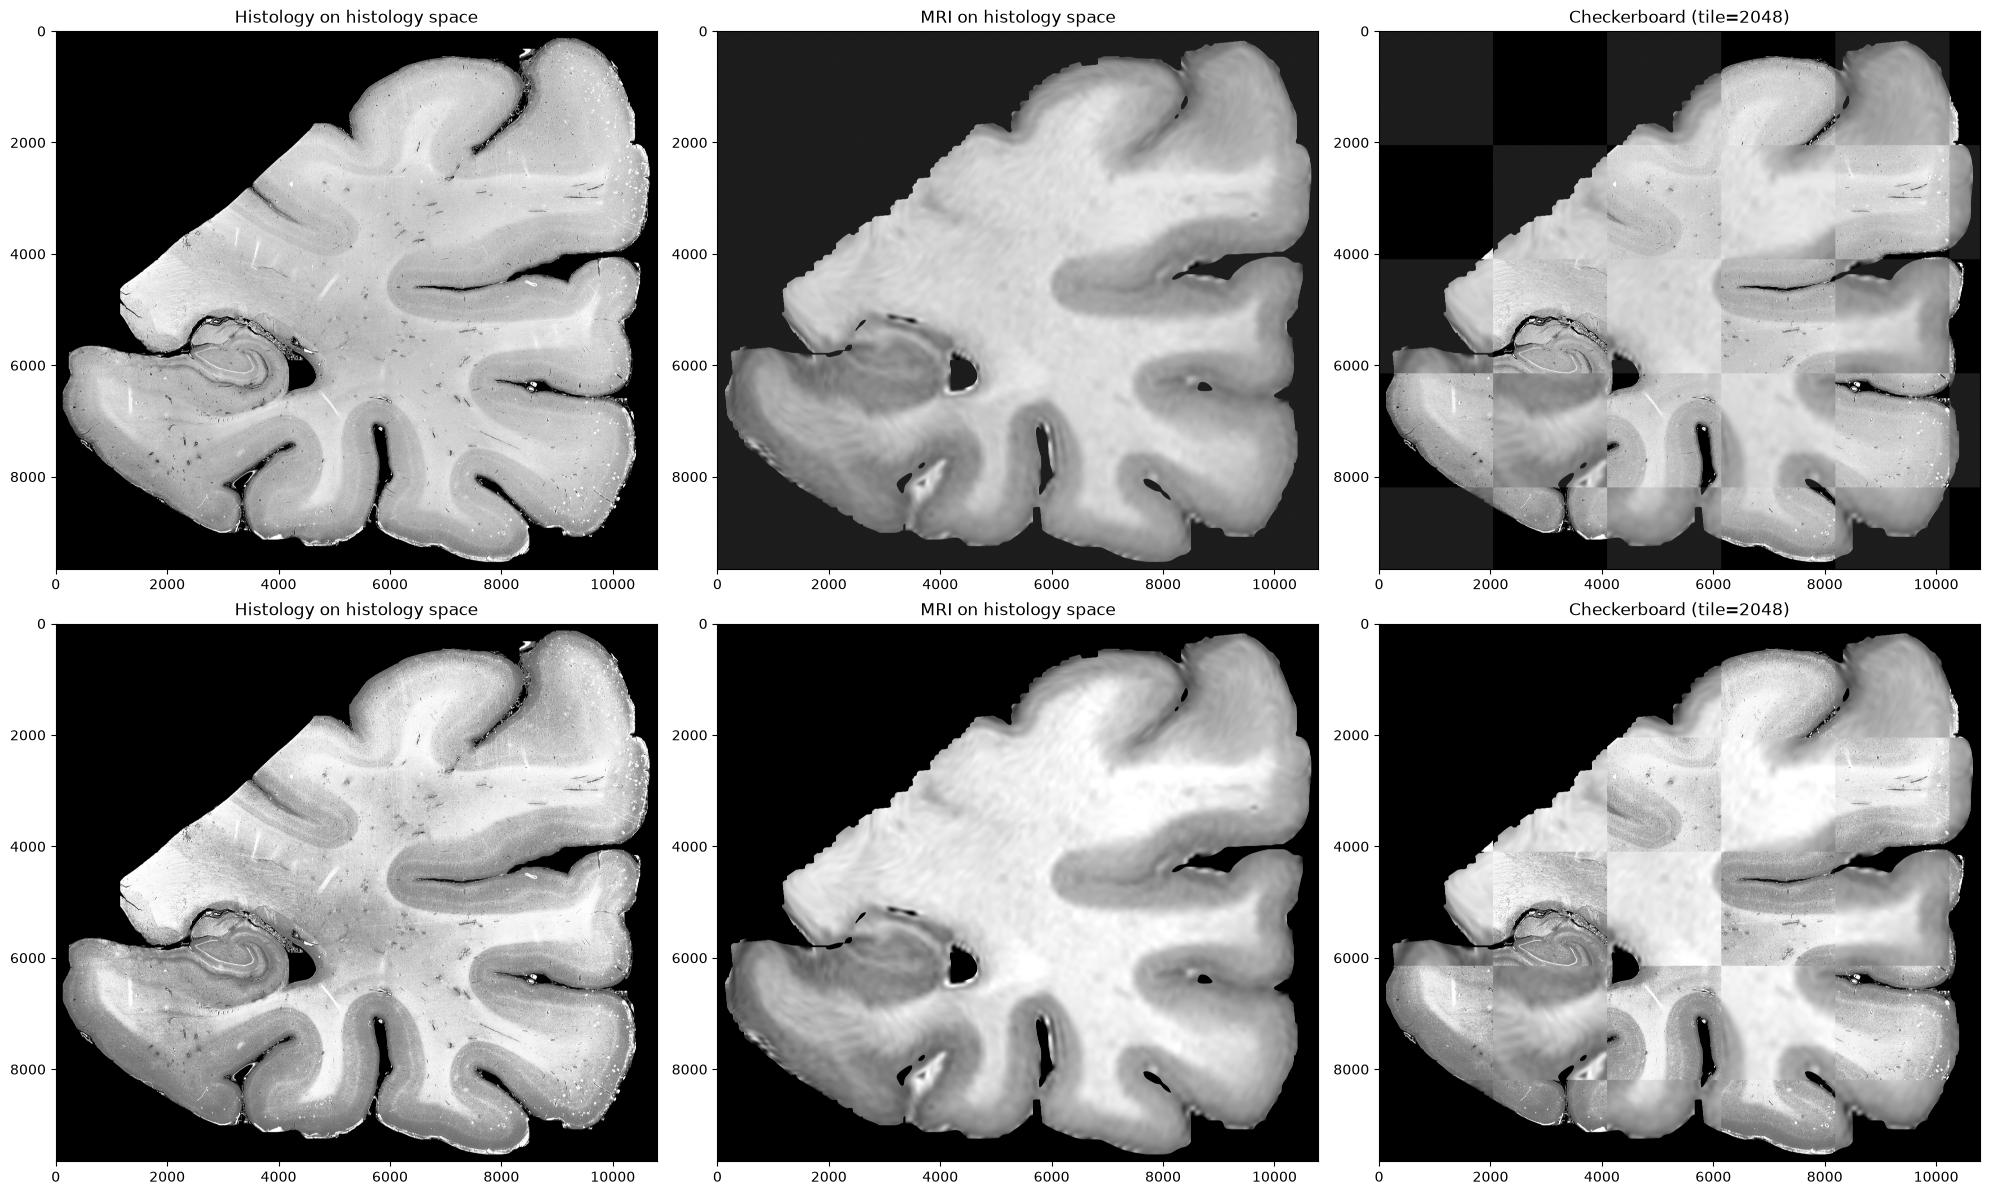

HR coverage: 0.656251


In [36]:
try:
    mri_on_hr, final_valid_hr, _, _, hr_info = inverse.mri_on_histology_space(
        Ih_hr=Ih_hr, Mh_hr=Mh_hr,
        proc_Ih=proc_Ih, scaled_proc_Ih=scaled_proc_Ih, A_hr_to_proc=A_hr_to_proc,
        oy_h=oy_h, ox_h=ox_h,
        slab_Im=slab_Im,
        xyz_norm_final=xyz_norm_final, xy_map_sym=xy_map_sym,
        valid_display=valid_display, mri_on_final_sheet=mri_on_final_sheet,
        device=device, tile_hw=512,
        show_proc_img=True, tile_size=MRI_ON_HISTO_TILE_SIZE,
        save_file=out_file("mri_on_histo_all.png"),
        save_file_single=out_file("mri_on_histo.png"),
        verbose=VERBOSE,
    )
    print(f"HR coverage: {final_valid_hr.mean():.6f}")
except ValueError as e:
    # Empty histology mask or empty valid_display: nothing to project.
    mri_on_hr = final_valid_hr = None
    print(f"dense HR QC skipped: {e}")

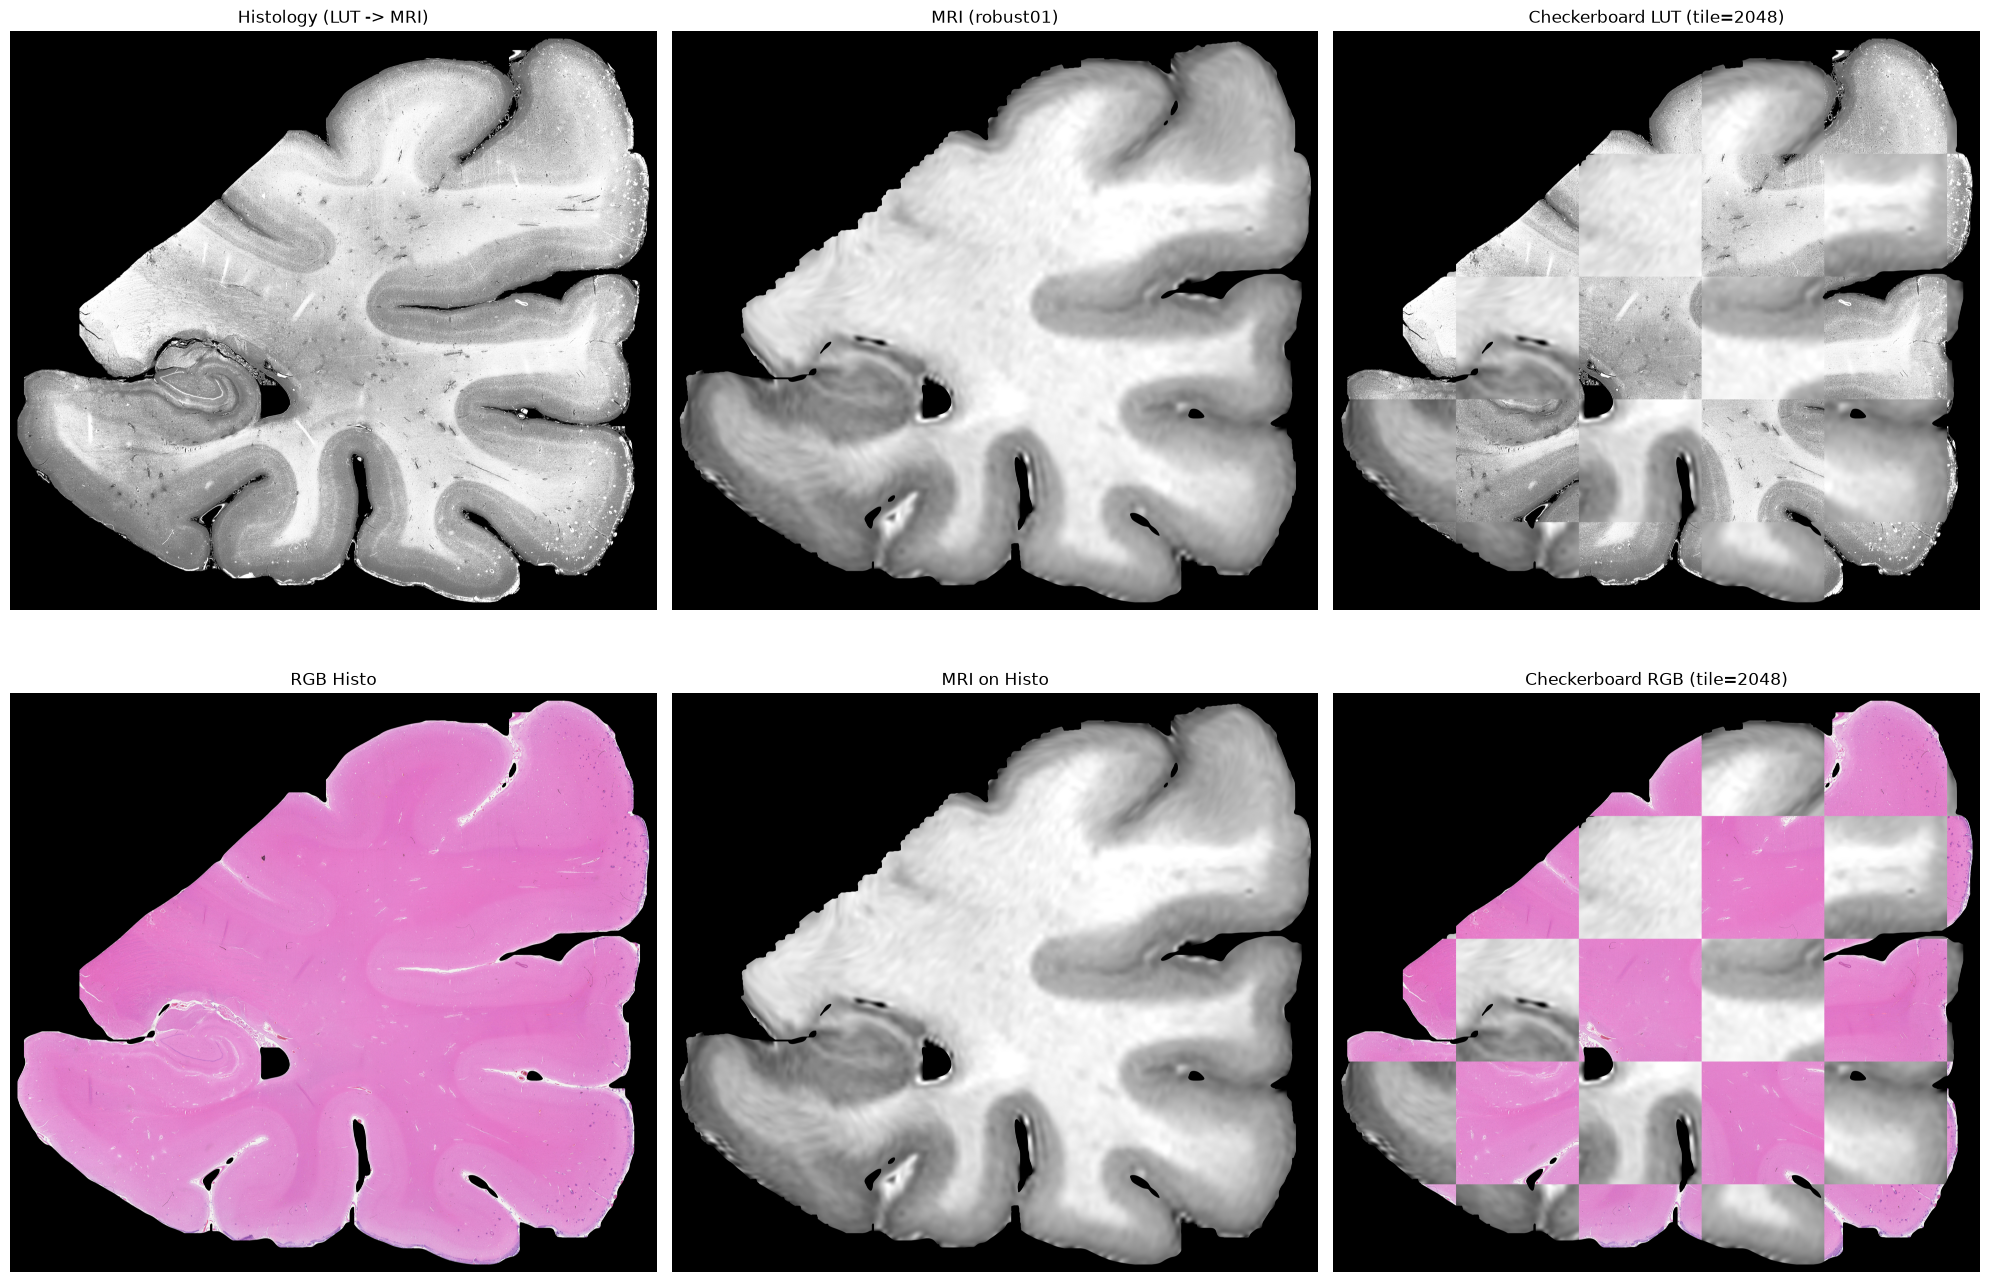

In [37]:
# Overlay on the RGB histology, when an RGB image exists.
if mri_on_hr is not None and Ih_rgb_hr is not None:
    arr_Ih_hr = sitk.GetArrayFromImage(Ih_hr)
    arr_Ih_hr_2d = arr_Ih_hr[0] if arr_Ih_hr.ndim == 3 and arr_Ih_hr.shape[0] == 1 else arr_Ih_hr
    arr_Ih_rgb_hr = sitk.GetArrayFromImage(Ih_rgb_hr)[0]
    qc.plot_mri_on_histology_rgb(arr_Ih_hr_2d, arr_Ih_rgb_hr, mri_on_hr,
                                 tile=MRI_ON_HISTO_TILE_SIZE,
                                 save_file=out_file("mri_on_histo_rgb.png"))
else:
    print("no RGB histology (or no HR projection): the RGB overlay is skipped")

## Step 19. The transform grid

What a batch run saves as `<section>_transform_grid.npz` (version 4). The fields and the
coordinate frames they live in are documented in the `register_section` docstring and in the
README. Besides the sheet itself, the file carries the frames needed to return to the files
this section came from: `A_hr_to_tif` undoes the rotation and flip to reach the cleanslide
TIFF, `crop_origin_xy` reaches the raw slide behind cleanslide's crop, and the `mri_*` fields
convert a sheet position to world millimetres or undo the permutation to reach the stored T1w.

Set `SAVE_TRANSFORM` in the configuration cell to write it from this notebook.

In [38]:
def to_np(x):
    # x as a numpy array (torch tensors are detached and moved to the CPU).
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)


grid = dict(
    A_common_to_hr=to_np(A_common_to_hr).astype(np.float64),
    xyz_norm_final=to_np(xyz_norm_final).astype(np.float32),
    xy_hist_map=to_np(xy_map_sym).astype(np.float32),
    valid_surf=to_np(valid_display).astype(np.uint8),
    ox_h=np.float64(ox_h),
    oy_h=np.float64(oy_h),
    G_e1=to_np(G["e1"]).astype(np.float64),
    G_e2=to_np(G["e2"]).astype(np.float64),
    mri_spacing=np.asarray(slab_Im.GetSpacing(), dtype=np.float64),
    mri_size=np.asarray(slab_Im.GetSize(), dtype=np.int64),
    mri_origin=np.asarray(slab_Im.GetOrigin(), dtype=np.float64),
    mri_direction=np.asarray(slab_Im.GetDirection(), dtype=np.float64),
    mri_permute=np.asarray(vols["mri_permute"], dtype=np.int64),
    mri_view_flip=np.asarray(vols["mri_view_flip"], dtype=bool),
    mri_orientation=np.array(vols["orientation"]),
    mri_canonical=np.array(vols["mri_canonical"]),
    mri_source=np.array(paths["mri"]),
    histo_on_surface=to_np(hist_on_init_tps).astype(np.float32),
    mri_on_surface=to_np(mri_on_final_sheet).astype(np.float32),
    A_hr_to_tif=np.asarray(vols["A_hr_to_tif"], dtype=np.float64),
    crop_origin_xy=np.asarray(vols["crop"]["crop_origin_xy"] or (-1, -1), dtype=np.int64),
    source_shape_hw=np.asarray(vols["crop"]["source_shape_hw"] or (-1, -1), dtype=np.int64),
    histo_source=np.array(paths["histo_gray"]),
    subject_id=np.array(paths["subject"]),
    sample=np.array(paths["sample"]),
    stain=np.array(paths["stain"]),
    section_id=np.array(SECTION_ID),
    profile=np.array(PROFILE),
    version=np.array([5], dtype=np.int32),
)
for k, v in grid.items():
    print(f"{k:<18} {np.asarray(v).dtype}  {np.asarray(v).shape}")

if SAVE_TRANSFORM:
    save_path = f"{PREFIX}_transform_grid.npz"
    np.savez_compressed(save_path, **grid)
    print("\nsaved ->", save_path)
else:
    print("\nSAVE_TRANSFORM is False; nothing written")

A_common_to_hr     float64  (4, 4)
xyz_norm_final     float32  (173, 181, 3)
xy_hist_map        float32  (173, 181, 2)
valid_surf         uint8  (173, 181)
ox_h               float64  ()
oy_h               float64  ()
G_e1               float64  (3,)
G_e2               float64  (3,)
mri_spacing        float64  (3,)
mri_size           int64  (3,)
mri_origin         float64  (3,)
mri_direction      float64  (9,)
mri_permute        int64  (3,)
mri_view_flip      bool  (3,)
mri_orientation    <U7  ()
mri_canonical      <U3  ()
mri_source         <U55  ()
histo_on_surface   float32  (173, 181)
mri_on_surface     float32  (173, 181)
A_hr_to_tif        float64  (4, 4)
crop_origin_xy     int64  (2,)
source_shape_hw    int64  (2,)
histo_source       <U107  ()
subject_id         <U11  ()
sample             <U12  ()
stain              <U2  ()
section_id         <U33  ()
profile            <U7  ()
version            int32  (1,)

SAVE_TRANSFORM is False; nothing written


## Summary

A compact record of what the steps decided for this section.

In [39]:
summary = pd.Series({
    "section": SECTION_ID,
    "from sidecar": f"{orientation}, rotation {rotation:g} deg, flip {flip}",
    "profile": PROFILE,
    "best scale": round(best_scale, 3),
    "patch / hist stride / mri stride": f"{best_patch} / {best_hist_stride} / {best_mri_stride}",
    "fine z window (slices)": f"{z_min}..{z_max}",
    "matches (all / coarse / clean)":
        f"{len(all_matches['matches'])} / {len(coarse_matches)} / {len(clean_matches)}",
    "TPS inliers (RANSAC / final)": f"{len(matches_inliers)} / {len(matches_inliers_final)}",
    "adaptive inlier threshold (vox)": round(adaptive_thresh, 2),
    "clamp_vox": round(clamp_vox, 2),
    "initial / final folding (%)": f"{fold_initial:.3f} / {fold_final:.3f}",
    "valid sheet fraction": round(float(valid_display.mean()), 4),
    "elapsed (s)": round(time.perf_counter() - section_start, 1),
}, name="value")
summary.to_frame()

,value
section,sub-NBEX919_sample-P2306_stain-HE
from sidecar,"coronal, rotation 0 deg, flip (True, False, Fa..."
profile,default
best scale,1.3
patch / hist stride / mri stride,64 / 32 / 4
fine z window (slices),192..312
matches (all / coarse / clean),18 / 12 / 10
TPS inliers (RANSAC / final),10 / 8
adaptive inlier threshold (vox),3.0
clamp_vox,8.0


In [40]:
# Free the GPU before running another section.
torch.cuda.empty_cache()